In [1]:
import pandas as pd 
import numpy as np 
import scanpy as sc
import pycisTopic
pycisTopic.__version__

import os
out_dir = "hm_outs"
os.makedirs(out_dir, exist_ok = True)

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


## get cell anno 

In [ ]:
"""
obs_list = []
path_list = ['/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter/cy_atac.h5ad',
             '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter/qf_atac.h5ad',
             '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter/jt_atac.h5ad',
             '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter/m_atac.h5ad',
             '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter/t_atac.h5ad'
]

for path in path_list:
    scdata = sc.read_h5ad(path)
    obs_list.append(scdata.obs.copy())

obs =  pd.concat(obs_list)

sample = []
for ele in obs.loc[:,'species'].values:
    sample.append(f'{ele}HM')
obs.loc[:,'sample'] = sample

new_idx = obs.index.values + '-' + np.array(sample)
obs.index = new_idx

obs.to_csv(os.path.join(out_dir,'cell_data.csv'), index = True)

cell_data = obs
"""

In [4]:
cell_data = pd.read_csv(os.path.join(out_dir,'cell_data.csv'), index_col = 0)
cell_data.head()

,leiden,eco,species,sample
AAACAGCCAATCCCTT-1-CYHM,1,eco,CY,CYHM
AAACAGCCACAGGAAT-1-CYHM,2,eco,CY,CYHM
AAACAGCCAGCAGGTA-1-CYHM,1,eco,CY,CYHM
AAACAGCCAGCATGAG-1-CYHM,1,eco,CY,CYHM
AAACATGCAAGGACCA-1-CYHM,7,eco,CY,CYHM


## get pseudobulk profiles from cell annotations

In [5]:
chromsizes = pd.read_table(
    "http://hgdownload.cse.ucsc.edu/goldenPath/mm10/bigZips/mm10.chrom.sizes",
    header = None,
    names = ["Chromosome", "End"]
)

chromsizes.insert(1, "Start", 0)
chromsizes.head()

fragments_dict = {'CYHM': '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter_fragments/cyhm_fragments/fragment.tsv.gz',
                'JTHM': '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter_fragments/jthm_fragments/fragment.tsv.gz',
                'QFHM': '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter_fragments/qfhm_fragments/fragment.tsv.gz',
                'MHM': '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter_fragments/mhm_fragments/fragment.tsv.gz',
                'THM': '/home/rsun@ZHANGroup.local/sly_data/grn_momics/data/filter_fragments/thm_fragments/fragment.tsv.gz'}

In [6]:
from pycisTopic.pseudobulk_peak_calling import export_pseudobulk
os.makedirs(os.path.join(out_dir, "consensus_peak_calling"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bed_files"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bw_files"), exist_ok = True)
os.makedirs(os.path.join(out_dir, 'temp'), exist_ok = True)

bw_paths, bed_paths = export_pseudobulk(
    input_data = cell_data,
    variable = "leiden",
    sample_id_col = "sample",
    chromsizes = chromsizes,
    bed_path = os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bed_files"),
    bigwig_path = os.path.join(out_dir, "consensus_peak_calling/pseudobulk_bw_files"),
    path_to_fragments = fragments_dict,
    n_cpu = 10,
    normalize_bigwig = True,
    temp_dir = os.path.join(out_dir, 'temp'),
    split_pattern = '-'
)

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-06-13 09:29:09,648	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2025-06-13 09:29:09,791 cisTopic     WARNING  Non-string values detected in leiden column. These will be converted to strings.
2025-06-13 09:29:09,879 cisTopic     INFO     Splitting fragments by cell type.
2025-06-13 09:30:30,227 cisTopic     INFO     generating bigwig files


/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. 

In [7]:
with open(os.path.join(out_dir, "consensus_peak_calling/bw_paths.tsv"), "wt") as f:
    for v in bw_paths:
        _ = f.write(f"{v}\t{bw_paths[v]}\n")

with open(os.path.join(out_dir, "consensus_peak_calling/bed_paths.tsv"), "wt") as f:
    for v in bed_paths:
        _ = f.write(f"{v}\t{bed_paths[v]}\n")

## infer consensus peaks using masc

In [8]:
bw_paths = {}
with open(os.path.join(out_dir, "consensus_peak_calling/bw_paths.tsv")) as f:
    for line in f:
        v, p = line.strip().split("\t")
        bw_paths.update({v: p})

bed_paths = {}
with open(os.path.join(out_dir, "consensus_peak_calling/bed_paths.tsv")) as f:
    for line in f:
        v, p = line.strip().split("\t")
        bed_paths.update({v: p})

from pycisTopic.pseudobulk_peak_calling import peak_calling
macs_path = "/home/rsun@ZHANGroup.local/anaconda3/envs/pyscenic/bin/macs2"

os.makedirs(os.path.join(out_dir, "consensus_peak_calling/MACS"), exist_ok = True)

narrow_peak_dict = peak_calling(
    macs_path = macs_path,
    bed_paths = bed_paths,
    outdir = os.path.join(os.path.join(out_dir, "consensus_peak_calling/MACS")),
    genome_size = 'hs',
    n_cpu = 10,
    input_format = 'BEDPE',
    shift = 73,
    ext_size = 146,
    keep_dup = 'all',
    q_value = 0.05,
    _temp_dir = None
)

2025-06-13 09:31:12,740	INFO worker.py:1724 -- Started a local Ray instance.
(pid=4135693) /home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
(pid=4135693)   from pkg_resources import DistributionNotFound, get_distribution


(macs_call_peak_ray pid=4135696) 2025-06-13 09:31:14,791 cisTopic     INFO     Calling peaks for 6 with /home/rsun@ZHANGroup.local/anaconda3/envs/pyscenic/bin/macs2 callpeak --treatment hm_outs/consensus_peak_calling/pseudobulk_bed_files/6.fragments.tsv.gz --name 6  --outdir hm_outs/consensus_peak_calling/MACS --format BEDPE --gsize hs --qvalue 0.05 --nomodel --shift 73 --extsize 146 --keep-dup all --call-summits --nolambda
(macs_call_peak_ray pid=4135696) 2025-06-13 09:32:05,178 cisTopic     INFO     6 done!
(macs_call_peak_ray pid=4135695) 2025-06-13 09:31:15,046 cisTopic     INFO     Calling peaks for 10 with /home/rsun@ZHANGroup.local/anaconda3/envs/pyscenic/bin/macs2 callpeak --treatment hm_outs/consensus_peak_calling/pseudobulk_bed_files/10.fragments.tsv.gz --name 10  --outdir hm_outs/consensus_peak_calling/MACS --format BEDPE --gsize hs --qvalue 0.05 --nomodel --shift 73 --extsize 146 --keep-dup all --call-summits --nolambda [repeated 9x across cluster] (Ray deduplicates logs by

(pid=4135697) /home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81. [repeated 9x across cluster]
(pid=4135697)   from pkg_resources import DistributionNotFound, get_distribution [repeated 9x across cluster]


In [9]:
from pycisTopic.iterative_peak_calling import get_consensus_peaks
# Other param
peak_half_width=250
path_to_blacklist="/home/rsun@ZHANGroup.local/projects_list/pycisTopic-main/blacklist/mm10-blacklist.v2.bed"
# Get consensus peaks
consensus_peaks = get_consensus_peaks(
    narrow_peaks_dict = narrow_peak_dict,
    peak_half_width = peak_half_width,
    chromsizes = chromsizes,
    path_to_blacklist = path_to_blacklist)

consensus_peaks.to_bed(
    path = os.path.join(out_dir, "consensus_peak_calling/consensus_regions.bed"),
    keep =True,
    compression = 'infer',
    chain = False)

2025-06-13 09:34:15,208 cisTopic     INFO     Extending and merging peaks per class
2025-06-13 09:34:37,805 cisTopic     INFO     Normalizing peak scores
2025-06-13 09:34:38,435 cisTopic     INFO     Merging peaks
Warning! Start and End columns now have different dtypes: int64 and int32
2025-06-13 09:35:45,111 cisTopic     INFO     Done!


/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pyranges/out.py:37: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  return pd.concat([outdf, df.get(noncanonical)], axis=1)
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pyranges/out.py:37: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  return pd.concat([outdf, df.get(noncanonical)], axis=1)
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pyranges/out.py:37: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  return pd.concat([outdf, df.get(noncanonical)], axis=1)
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pyranges/out.py:37: FutureWarning: Passing a set as an indexer is deprecated and will raise in a fu

## QC

In [11]:
!pycistopic tss gene_annotation_list | grep Mouse
!mkdir -p hm_outs/qc
!pycistopic tss get_tss \
    --output hm_outs/qc/tss.bed \
    --name "mmusculus_gene_ensembl" \
    --to-chrom-source ucsc \
    --ucsc mm10
!head hm_outs/qc/tss.bed | column -t

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
mmurinus_gene_ensembl	Mouse Lemur genes (Mmur_3.0)
mmusculus_gene_ensembl	Mouse genes (GRCm39)
/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
- Get TSS annotation from Ensembl BioMart with the following settings:


In [12]:
## calculate qc metrics parallel 

regions_bed_filename = os.path.join(out_dir, "consensus_peak_calling/consensus_regions.bed")
tss_bed_filename = os.path.join(out_dir, "qc", "tss.bed")

pycistopic_qc_commands_filename = "pycistopic_qc_commands.txt"

# Create text file with all pycistopic qc command lines.
with open(pycistopic_qc_commands_filename, "w") as fh:
    for sample, fragment_filename in fragments_dict.items():
        print(
            "pycistopic qc",
            f"--fragments {fragment_filename}",
            f"--regions {regions_bed_filename}",
            f"--tss {tss_bed_filename}",
            f"--output {os.path.join(out_dir, 'qc')}/{sample}",
            sep=" ",
            file=fh,
        )

!cat pycistopic_qc_commands.txt | parallel -j 5 {}

Academic tradition requires you to cite works you base your article on.
If you use programs that use GNU Parallel to process data for an article in a
scientific publication, please cite:

  Tange, O. (2025, April 22). GNU Parallel 20250422 ('Tariffs').
  Zenodo. https://doi.org/10.5281/zenodo.15265748

This helps funding further development; AND IT WON'T COST YOU A CENT.
If you pay 10000 EUR you should feel free to use GNU Parallel without citing.

More about funding GNU Parallel and the citation notice:
https://www.gnu.org/software/parallel/parallel_design.html#citation-notice

To silence this citation notice: run 'parallel --citation' once.

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/pycisTopic/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81

### qc plot

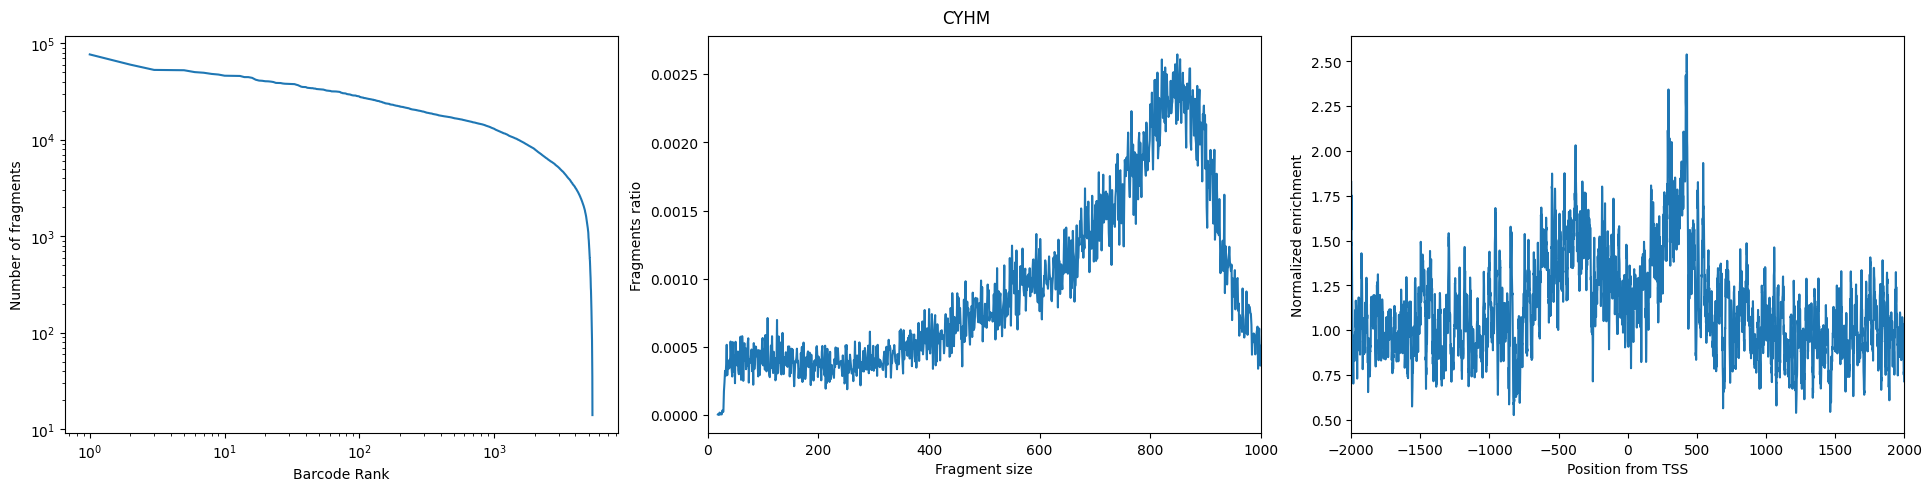

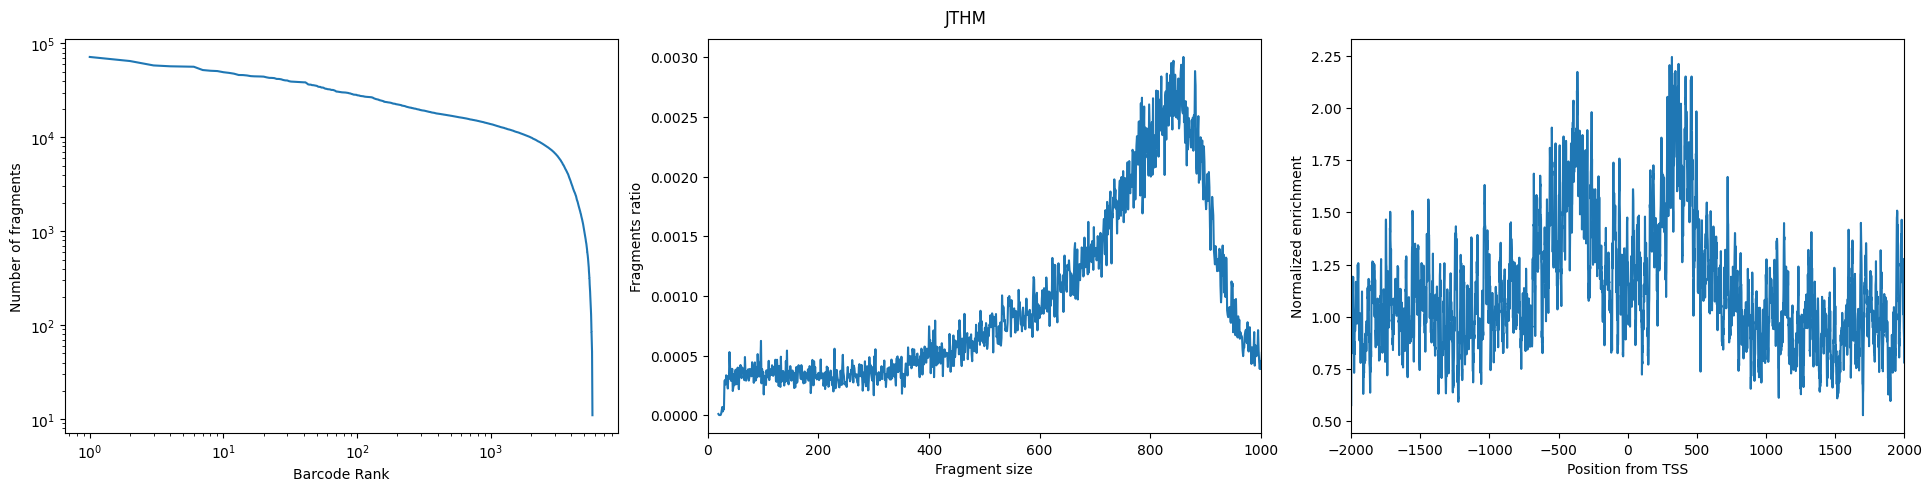

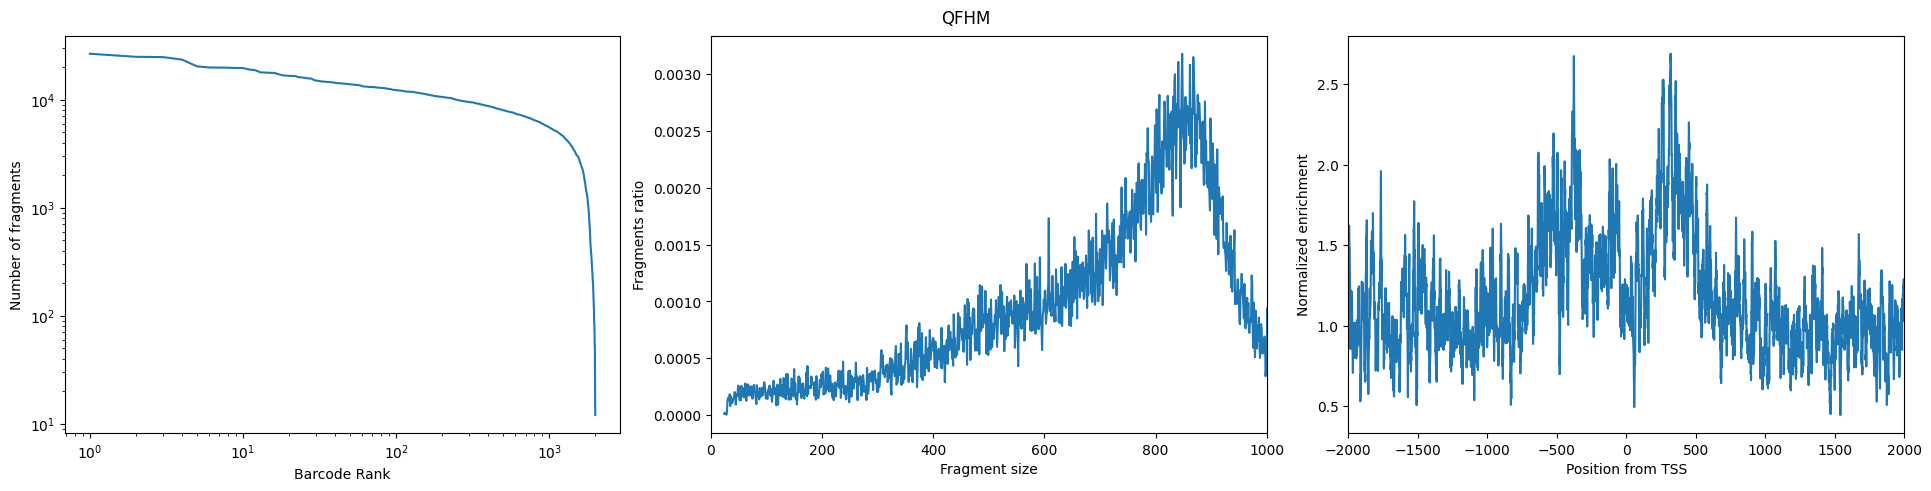

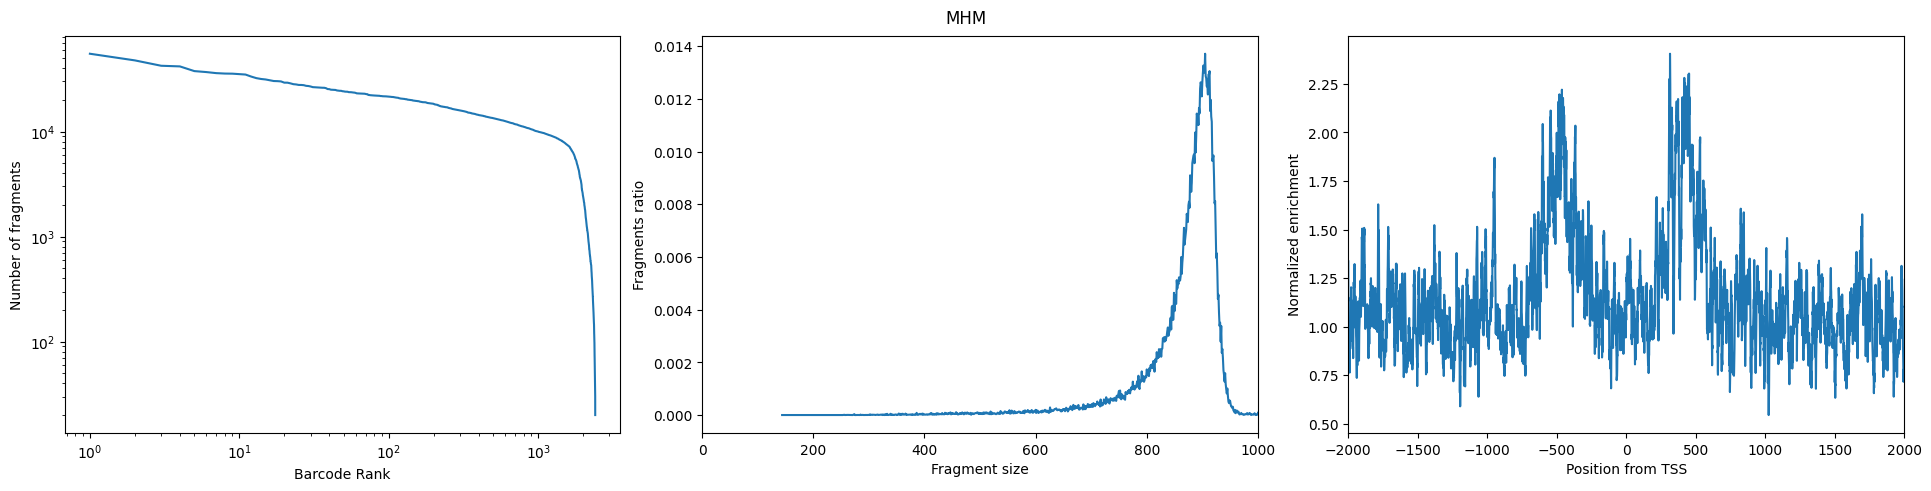

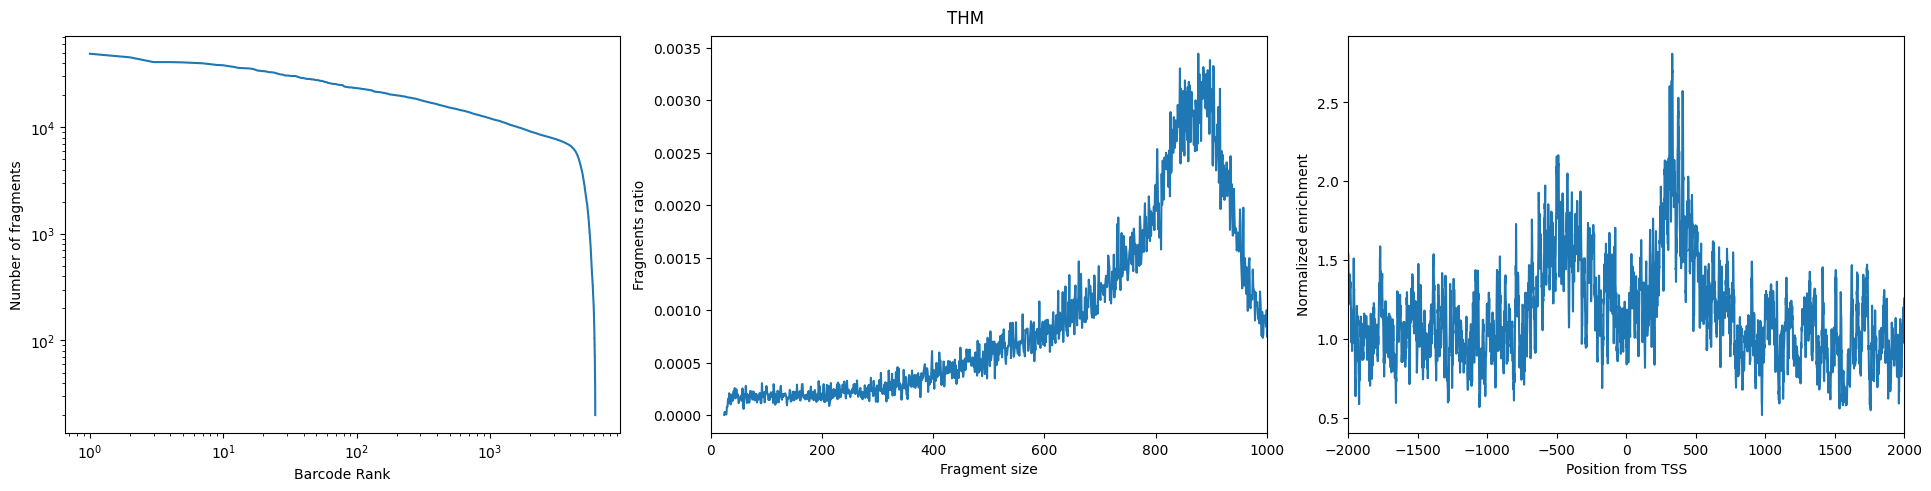

In [13]:
from pycisTopic.plotting.qc_plot import plot_sample_stats, plot_barcode_stats
import matplotlib.pyplot as plt

for sample_id in fragments_dict:
    fig = plot_sample_stats(
        sample_id = sample_id,
        pycistopic_qc_output_dir = "hm_outs/qc"
    )
## 看中间的图的话，这个peak calling的结果是有问题的...

CYHM:
	Using automatic threshold for unique fragments: 3783.670111896819
	Using automatic threshold for TSS enrichment: 1.2950464108910889
JTHM:
	Using automatic threshold for unique fragments: 2778.43671031798
	Using automatic threshold for TSS enrichment: 1.3145079207920793
QFHM:
	Using automatic threshold for unique fragments: 1805.7002065479237
	Using automatic threshold for TSS enrichment: 1.282224044895028
MHM:
	Using automatic threshold for unique fragments: 2733.819797495713
	Using automatic threshold for TSS enrichment: 1.2213274581547084
THM:
	Using automatic threshold for unique fragments: 2320.3759965750723
	Using automatic threshold for TSS enrichment: 1.2612843653043144


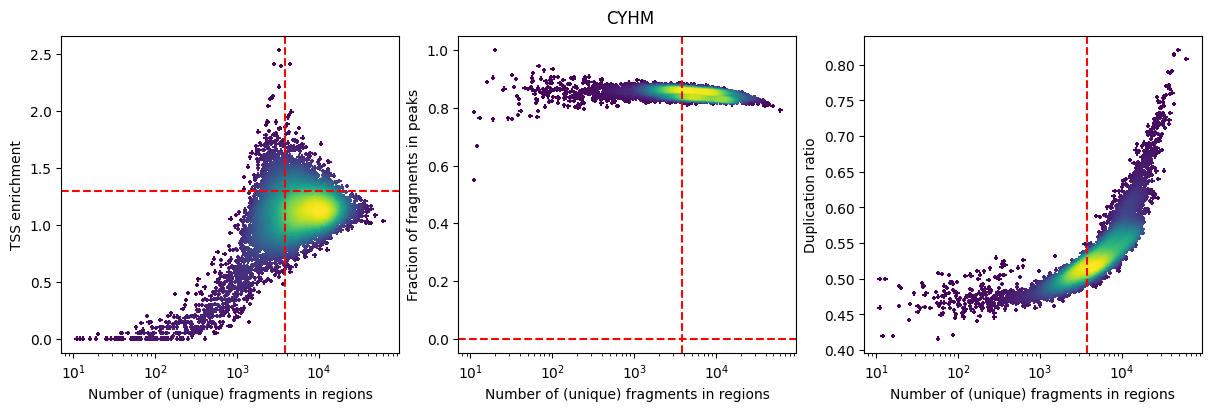

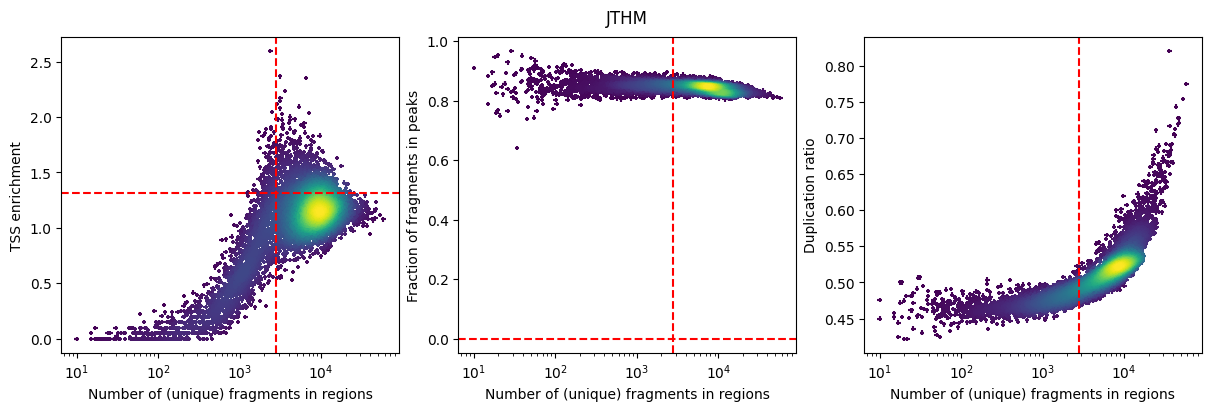

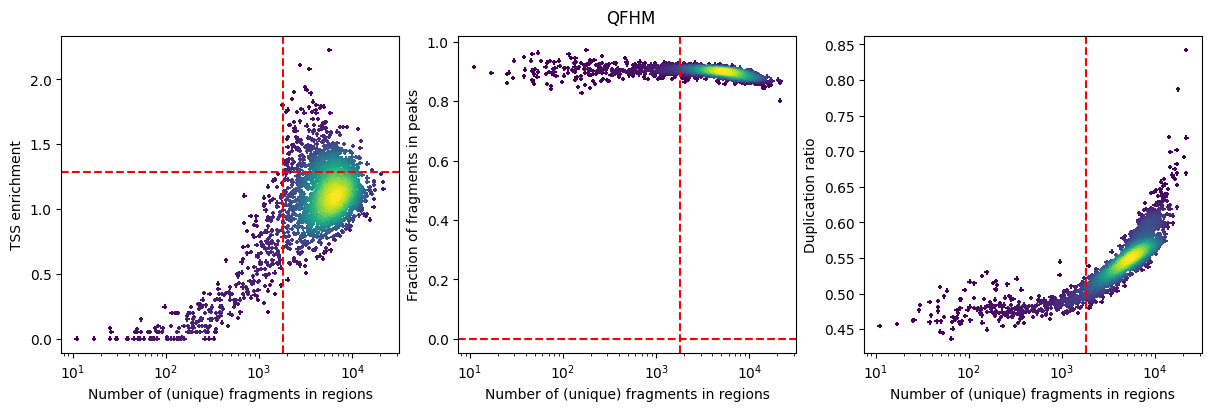

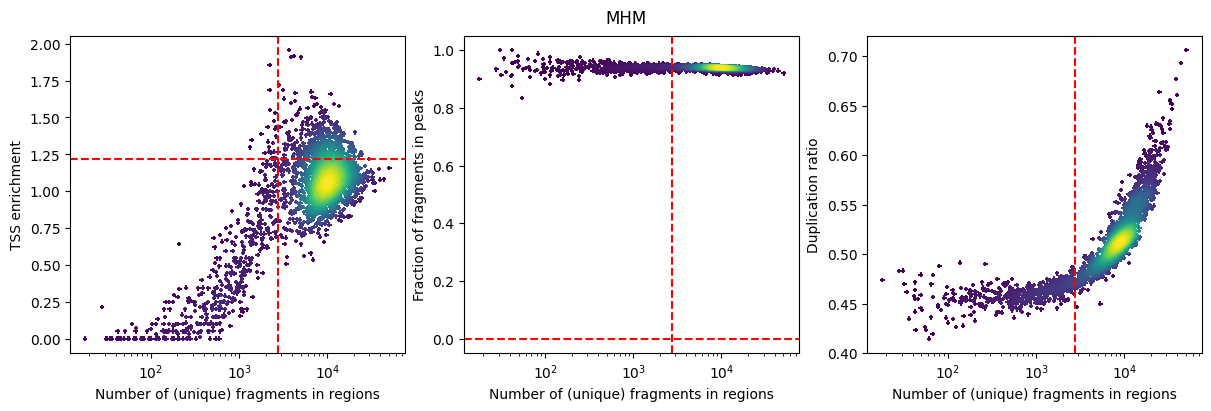

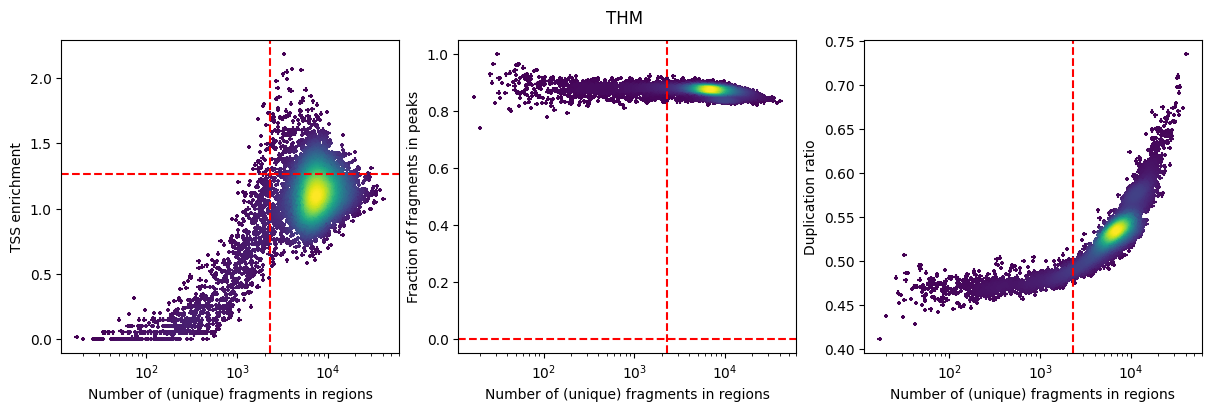

In [14]:
from pycisTopic.qc import get_barcodes_passing_qc_for_sample
sample_id_to_barcodes_passing_filters = {}
sample_id_to_thresholds = {}

for sample_id in fragments_dict:
    (
        sample_id_to_barcodes_passing_filters[sample_id],
        sample_id_to_thresholds[sample_id]
    ) = get_barcodes_passing_qc_for_sample(
            sample_id = sample_id,
            pycistopic_qc_output_dir = os.path.join(out_dir,'qc'),
            unique_fragments_threshold = None, # use automatic thresholding
            tss_enrichment_threshold = None, # use automatic thresholding
            frip_threshold = 0,
            use_automatic_thresholds = True,
    )

for sample_id in fragments_dict:
    fig = plot_barcode_stats(
        sample_id = sample_id,
        pycistopic_qc_output_dir = os.path.join(out_dir,'qc'),
        bc_passing_filters = sample_id_to_barcodes_passing_filters[sample_id],
        detailed_title = False,
        **sample_id_to_thresholds[sample_id]
    )

## TSS 分数很低

## create cistopic object

In [15]:
path_to_regions = os.path.join(out_dir, "consensus_peak_calling/consensus_regions.bed")
#path_to_blacklist = "pycisTopic/blacklist/hg38-blacklist.v2.bed"
path_to_blacklist="/home/rsun@ZHANGroup.local/projects_list/pycisTopic-main/blacklist/mm10-blacklist.v2.bed"
pycistopic_qc_output_dir = os.path.join(out_dir,'qc')

from pycisTopic.cistopic_class import create_cistopic_object_from_fragments
import polars as pl

cistopic_obj_list = []
for sample_id in fragments_dict:
    sample_metrics = pl.read_parquet(
        os.path.join(pycistopic_qc_output_dir, f'{sample_id}.fragments_stats_per_cb.parquet')
    ).to_pandas().set_index("CB").loc[ sample_id_to_barcodes_passing_filters[sample_id] ]
    cistopic_obj = create_cistopic_object_from_fragments(
        path_to_fragments = fragments_dict[sample_id],
        path_to_regions = path_to_regions,
        path_to_blacklist = path_to_blacklist,
        metrics = sample_metrics,
        valid_bc = sample_id_to_barcodes_passing_filters[sample_id],
        n_cpu = 1,
        project = sample_id,
        split_pattern = '-'
    )
    cistopic_obj_list.append(cistopic_obj)

2025-06-13 09:37:05,507 cisTopic     INFO     Reading data for CYHM
2025-06-13 09:37:27,602 cisTopic     INFO     metrics provided!
2025-06-13 09:37:28,629 cisTopic     INFO     Counting fragments in regions
2025-06-13 09:37:30,438 cisTopic     INFO     Creating fragment matrix
2025-06-13 09:37:33,219 cisTopic     INFO     Converting fragment matrix to sparse matrix
2025-06-13 09:37:33,607 cisTopic     INFO     Removing blacklisted regions
2025-06-13 09:37:33,910 cisTopic     INFO     Creating CistopicObject
2025-06-13 09:37:34,085 cisTopic     INFO     Done!
2025-06-13 09:37:34,115 cisTopic     INFO     Reading data for JTHM
2025-06-13 09:37:59,468 cisTopic     INFO     metrics provided!
2025-06-13 09:38:00,484 cisTopic     INFO     Counting fragments in regions
2025-06-13 09:38:03,178 cisTopic     INFO     Creating fragment matrix
2025-06-13 09:38:07,741 cisTopic     INFO     Converting fragment matrix to sparse matrix
2025-06-13 09:38:08,369 cisTopic     INFO     Removing blackliste

In [29]:
for ele in cistopic_obj_list:
    ## 只有很少的细胞能通过QC
    print(ele)

CistopicObject from project CYHM with n_cells × n_regions = 628 × 100050
CistopicObject from project JTHM with n_cells × n_regions = 865 × 119459
CistopicObject from project QFHM with n_cells × n_regions = 399 × 65901
CistopicObject from project MHM with n_cells × n_regions = 431 × 128405
CistopicObject from project THM with n_cells × n_regions = 1161 × 109110


In [27]:
from pycisTopic.cistopic_class import merge 

cistopic_obj = merge(cistopic_obj_list, split_pattern = '-')
print(cistopic_obj)

import pickle
pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj.pkl"), "wb")
)

2025-06-13 09:42:19,050 cisTopic     INFO     cisTopic object 1 merged
2025-06-13 09:42:20,378 cisTopic     INFO     cisTopic object 2 merged
2025-06-13 09:42:22,562 cisTopic     INFO     cisTopic object 3 merged
2025-06-13 09:42:25,744 cisTopic     INFO     cisTopic object 4 merged
CistopicObject from project cisTopic_merge with n_cells × n_regions = 3484 × 252047


In [28]:
import pandas as pd
#cell_data = pd.read_table("data/cell_data.tsv", index_col = 0)
#cell_data.head()
cistopic_obj.add_cell_data(cell_data, split_pattern='-')
pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj.pkl"), "wb")
)
cistopic_obj.cell_data.head()

,cisTopic_nr_frag,cisTopic_log_nr_frag,cisTopic_nr_acc,cisTopic_log_nr_acc,sample_id,barcode_rank,total_fragments_count,log10_total_fragments_count,unique_fragments_count,log10_unique_fragments_count,...,nucleosome_signal,tss_enrichment,pdf_values_for_tss_enrichment,pdf_values_for_fraction_of_fragments_in_peaks,pdf_values_for_duplication_ratio,barcode,leiden,eco,species,sample
CTTGCTCAGAAAGCAT-1-CYHM,12290,4.089552,12269,4.088809,CYHM,816,32842,4.516443,14472,4.160559,...,1.196949,1.422970,0.434937,21.792894,14.253199,CTTGCTCAGAAAGCAT-1,2,eco,CY,CYHM
CAGAACCGTTACATCC-1-CYHM,10105,4.004536,10084,4.003633,CYHM,1222,29251,4.466156,11481,4.060018,...,1.176806,1.323530,1.096504,9.618882,3.007973,CAGAACCGTTACATCC-1,8,eco,CY,CYHM
TTTGACCGTTAATGCG-1-CYHM,10415,4.017659,10392,4.016699,CYHM,1131,27531,4.439838,11984,4.078638,...,1.152482,1.581186,0.120326,22.398260,12.139823,TTTGACCGTTAATGCG-1,0,eco,CY,CYHM
TAGCTAGGTGCTAGCG-1-CYHM,6200,3.792392,6190,3.791691,CYHM,2201,14990,4.175831,7184,3.856427,...,1.125364,1.565093,0.315045,20.986303,21.325978,TAGCTAGGTGCTAGCG-1,2,eco,CY,CYHM
AAGAATCAGTAAGTCC-1-CYHM,12217,4.086965,12193,4.086111,CYHM,852,33854,4.529623,14214,4.152747,...,1.161808,1.304582,1.116344,15.849984,6.953876,AAGAATCAGTAAGTCC-1,4,eco,CY,CYHM


In [30]:
pd.crosstab(cistopic_obj.cell_data.loc[:,'species'], cistopic_obj.cell_data.loc[:,'leiden'])

leiden,0,1,2,3,4,5,6,7,8,9,10
species,,,,,,,,,,,
CY,191,77,150,0,95,0,55,16,36,8,0
JT,213,172,162,8,108,0,111,37,51,3,0
M,0,45,7,89,3,161,0,18,22,47,39
QF,0,106,3,145,0,82,0,24,6,4,29
T,763,44,33,144,5,0,6,52,29,30,55


## run models

In [31]:
lda_path = os.path.join(out_dir, 'lda_models')
os.makedirs(lda_path, exist_ok=True)
os.environ['MALLET_MEMORY'] = '200G'
from pycisTopic.lda_models import run_cgs_models_mallet
# Configure path Mallet
mallet_path="/home/rsun@ZHANGroup.local/projects_list/Mallet-202108/bin/mallet"
# Run models
models=run_cgs_models_mallet(
    cistopic_obj,
    n_topics=[2, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50],
    n_cpu=128,
    n_iter=500,
    random_state=555,
    alpha=50,
    alpha_by_topic=True,
    eta=0.1,
    eta_by_topic=False,
    tmp_path=lda_path,
    save_path=lda_path,
    mallet_path=mallet_path,
)

2025-06-13 09:43:37,969 cisTopic     INFO     Formatting input to corpus
2025-06-13 09:43:38,313 cisTopic     INFO     Running model with 2 topics
2025-06-13 09:43:38,314 LDAMalletWrapper INFO     Serializing temporary corpus to hm_outs/lda_models/corpus.txt
2025-06-13 09:43:49,651 LDAMalletWrapper INFO     Converting temporary corpus to MALLET format with: /home/rsun@ZHANGroup.local/projects_list/Mallet-202108/bin/mallet import-file --preserve-case --keep-sequence --token-regex \S+ --input hm_outs/lda_models/corpus.txt --output hm_outs/lda_models/corpus.mallet
2025-06-13 09:43:59,626 LDAMalletWrapper INFO     Training MALLET LDA with: /home/rsun@ZHANGroup.local/projects_list/Mallet-202108/bin/mallet train-topics --input hm_outs/lda_models/corpus.mallet --num-topics 2 --alpha 50 --beta 0.1 --optimize-interval 0 --num-threads 128 --output-state hm_outs/lda_models/e2c57b_state.mallet.gz --output-doc-topics hm_outs/lda_models/e2c57b_doctopics.txt --output-topic-keys hm_outs/lda_models/e2c

In [32]:
pickle.dump(
    models,
    open(os.path.join(lda_path, "models.pkl"), "wb")
)

## model selection

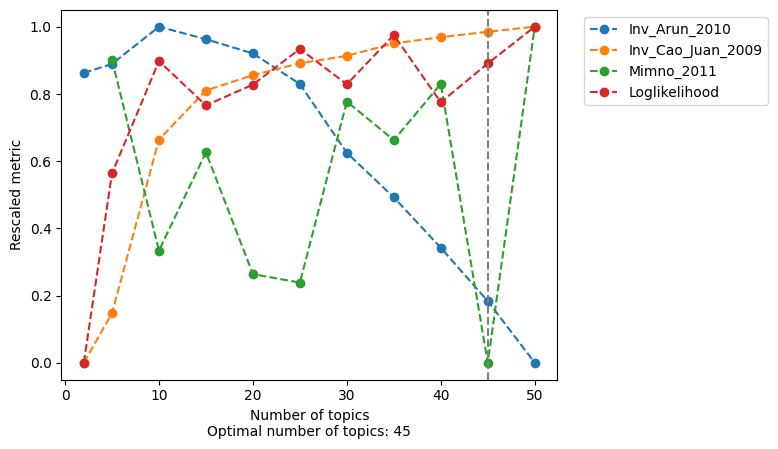

In [33]:
from pycisTopic.lda_models import evaluate_models
model = evaluate_models(
    models,
    select_model = 45,
    return_model = True
)

In [34]:
cistopic_obj.add_LDA_model(model)
pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj.pkl"), "wb")
)

## cluster and vis

2025-06-15 06:01:40,086 cisTopic     INFO     Finding neighbours


Columns ['pycisTopic_leiden_10_1'] will be overwritten
2025-06-15 06:01:40,479 cisTopic     INFO     Running UMAP


/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


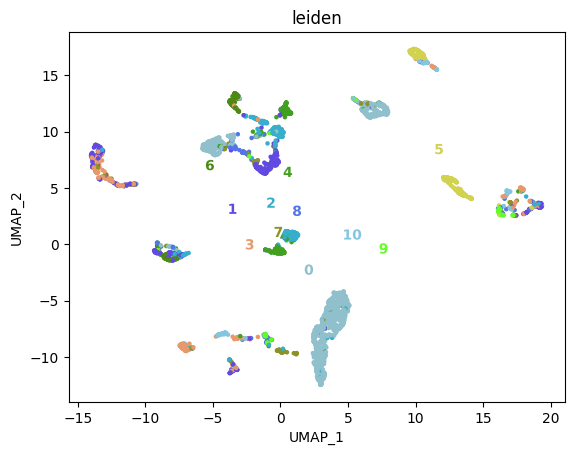

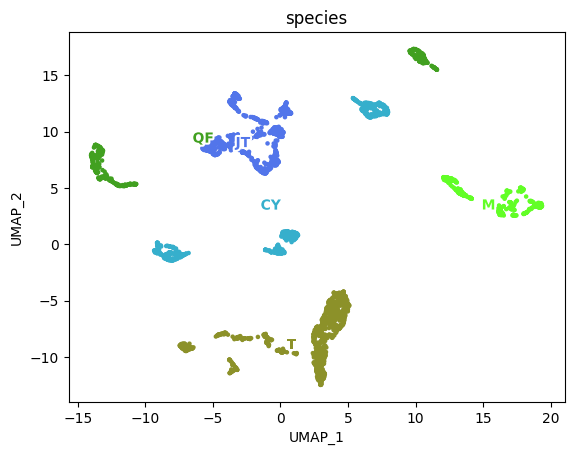

In [57]:
from pycisTopic.clust_vis import (
    find_clusters,
    run_umap,
    run_tsne,
    plot_metadata,
    plot_topic,
    cell_topic_heatmap
)

find_clusters(
    cistopic_obj,
    target  = 'cell',
    k = 10,
    res = [1],
    prefix = 'pycisTopic_',
    scale = True,
    split_pattern = '-'
)

run_umap(
    cistopic_obj,
    target  = 'cell', scale=True)

tmp = []
for i,ele in enumerate(cistopic_obj.cell_data.leiden.values):
    tmp.append(str(ele))
cistopic_obj.cell_data.loc[:,'leiden'] = tmp
cistopic_obj.cell_data.leiden

plot_metadata(
    cistopic_obj,
    reduction_name='UMAP',
    variables=['leiden','species'],
    target='cell',
    text_size=10,
    dot_size=5)

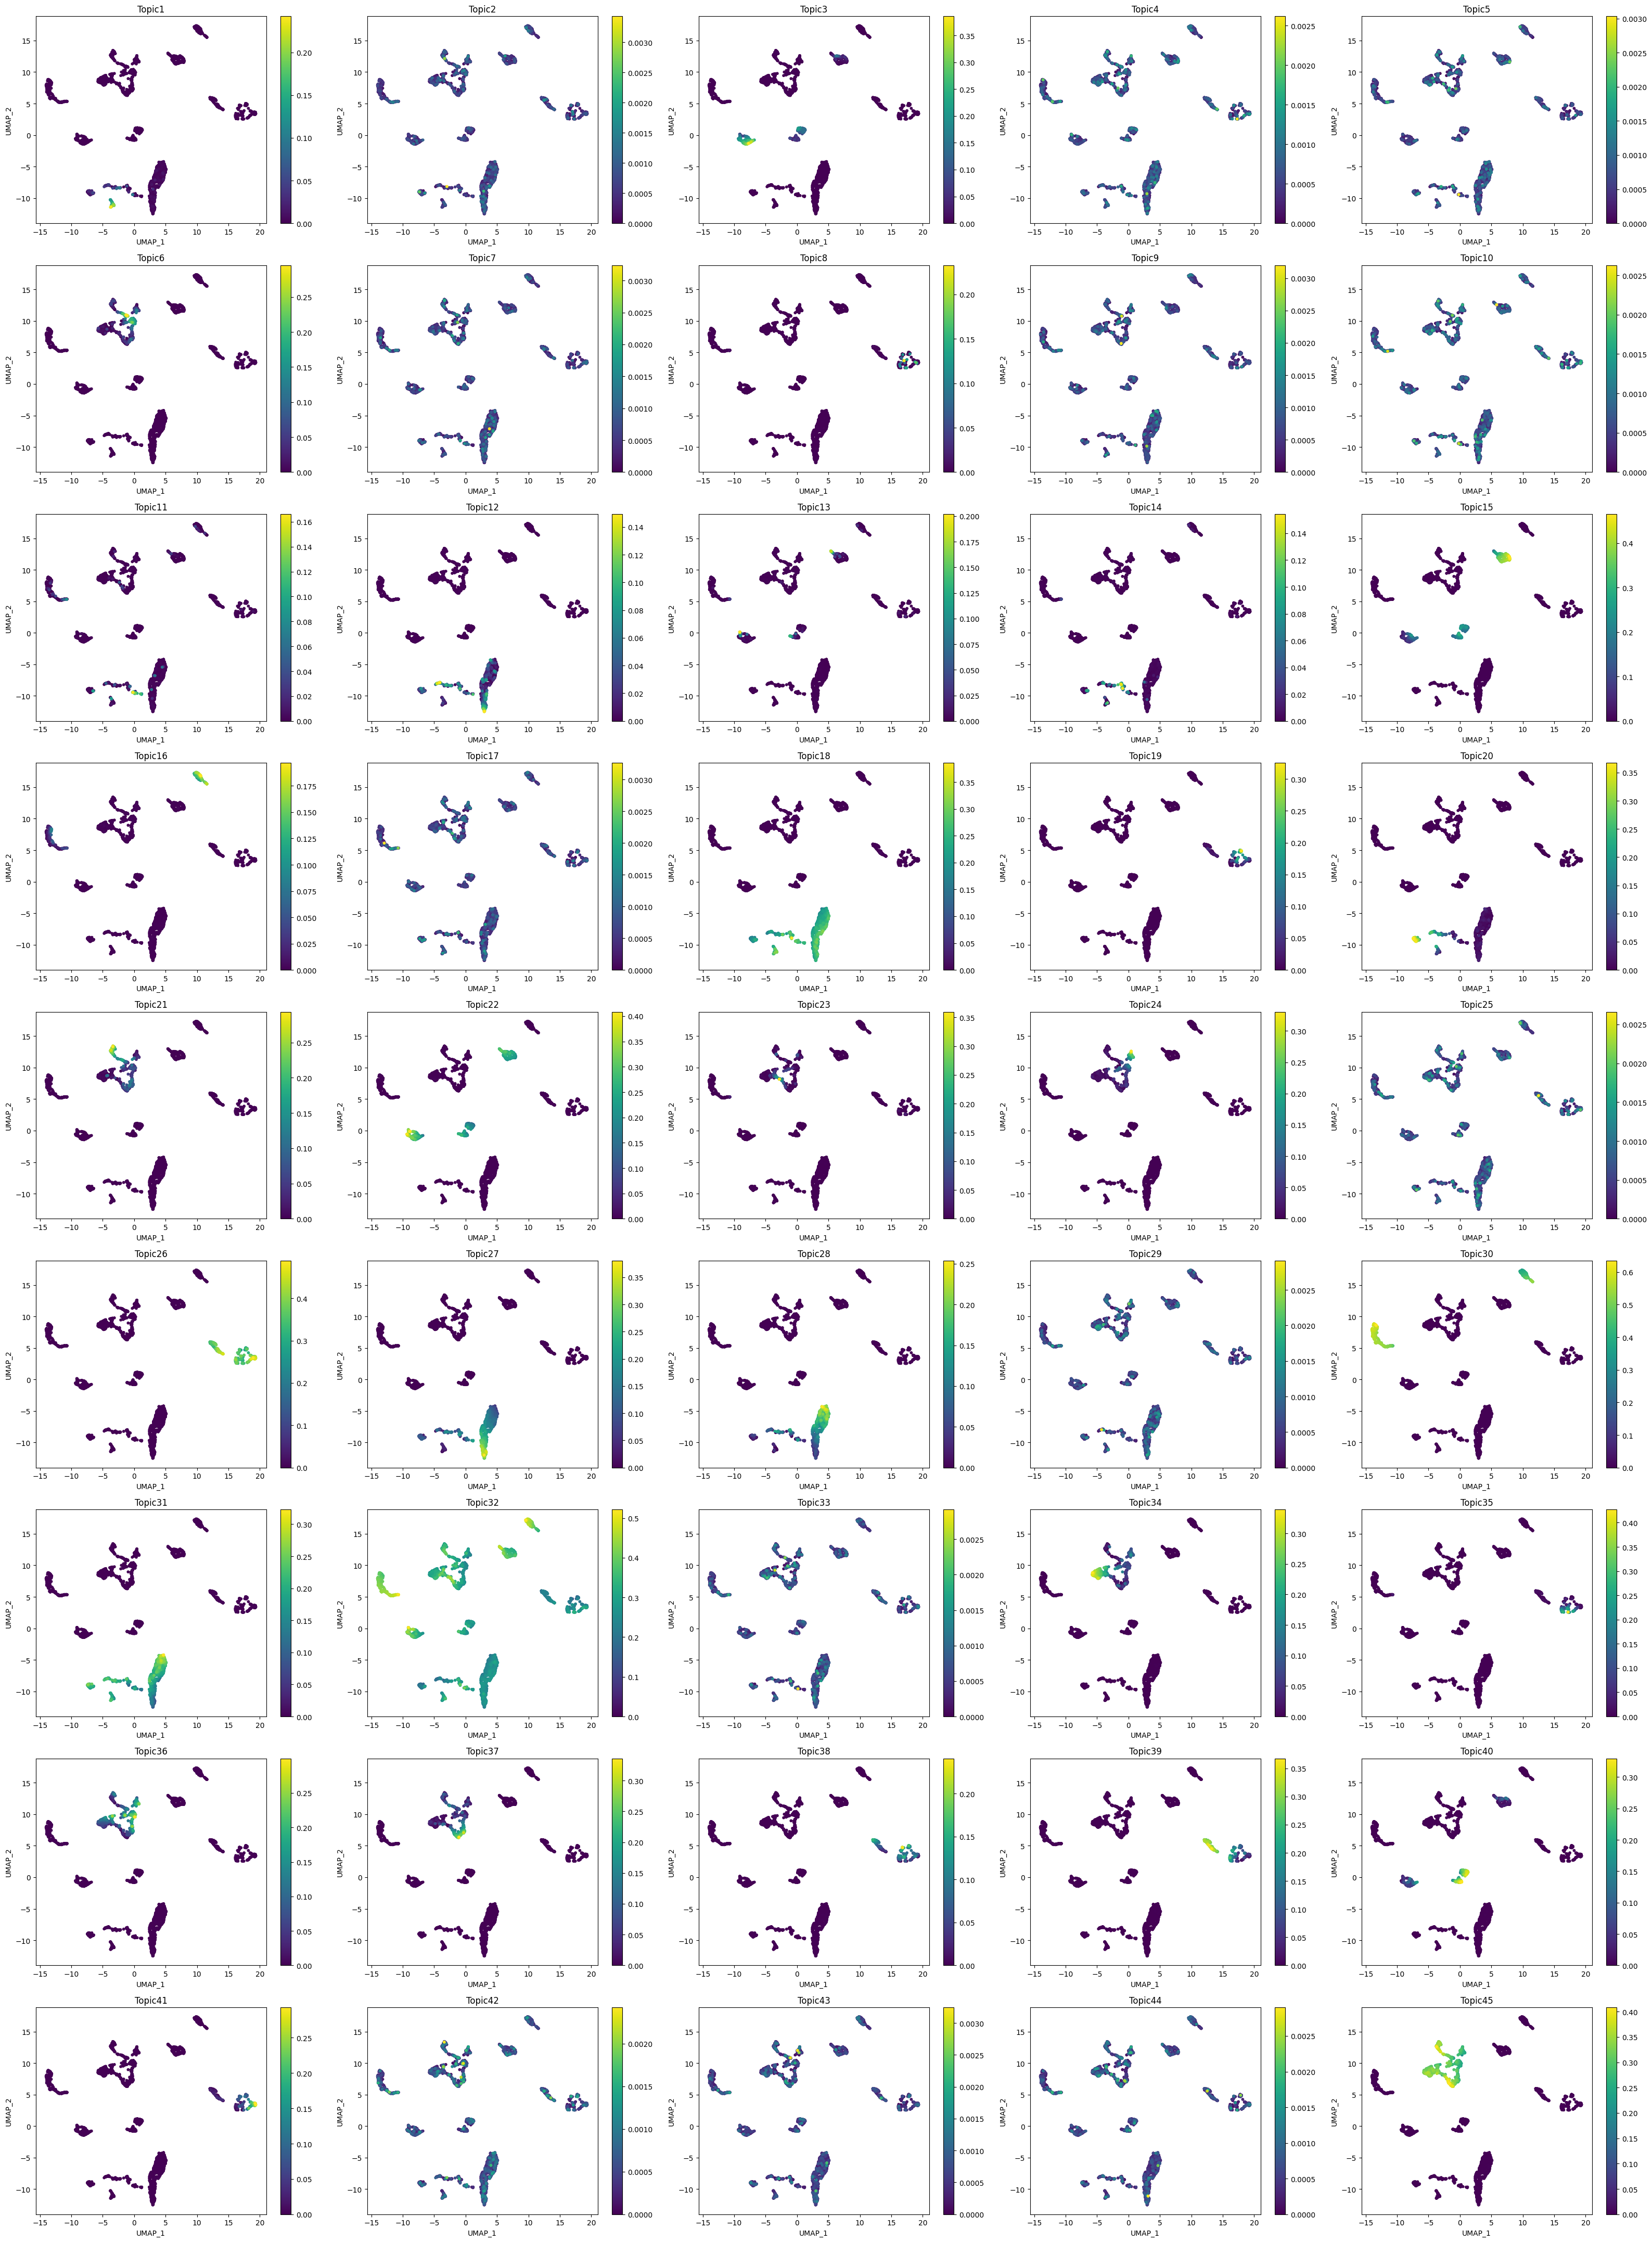

In [58]:
plot_topic(
    cistopic_obj,
    reduction_name = 'UMAP',
    target = 'cell',
    num_columns=5
)

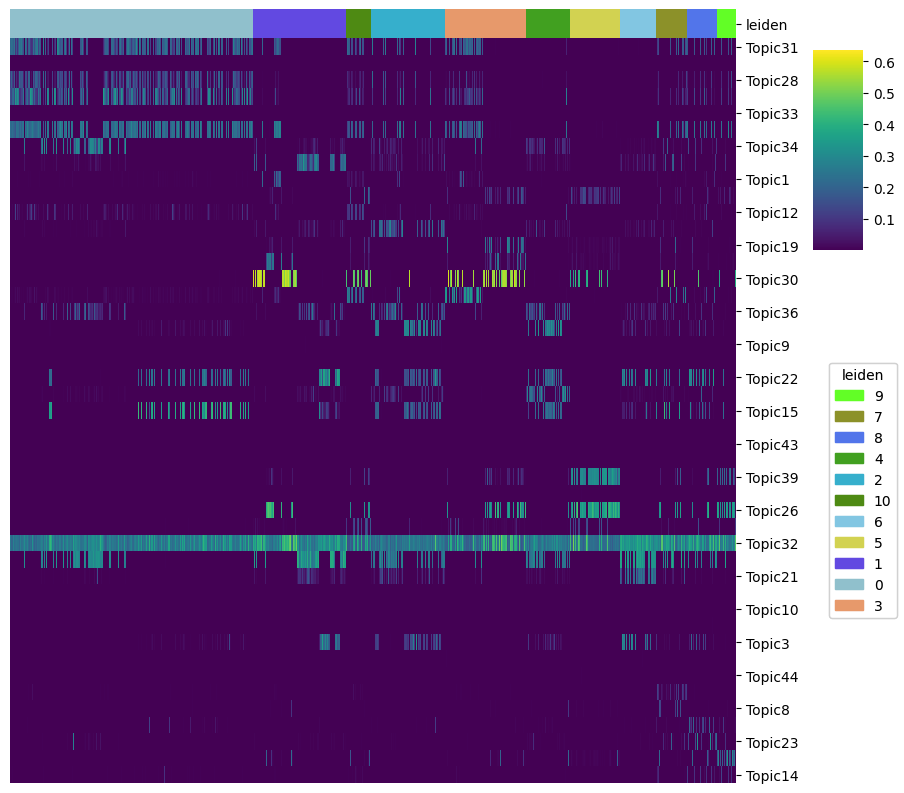

In [59]:
cell_topic_heatmap(
    cistopic_obj,
    variables = ['leiden'],
    scale = False,
    legend_loc_x = 1.0,
    legend_loc_y = -1.2,
    legend_dist_y = -1,
    figsize = (10, 10)
)

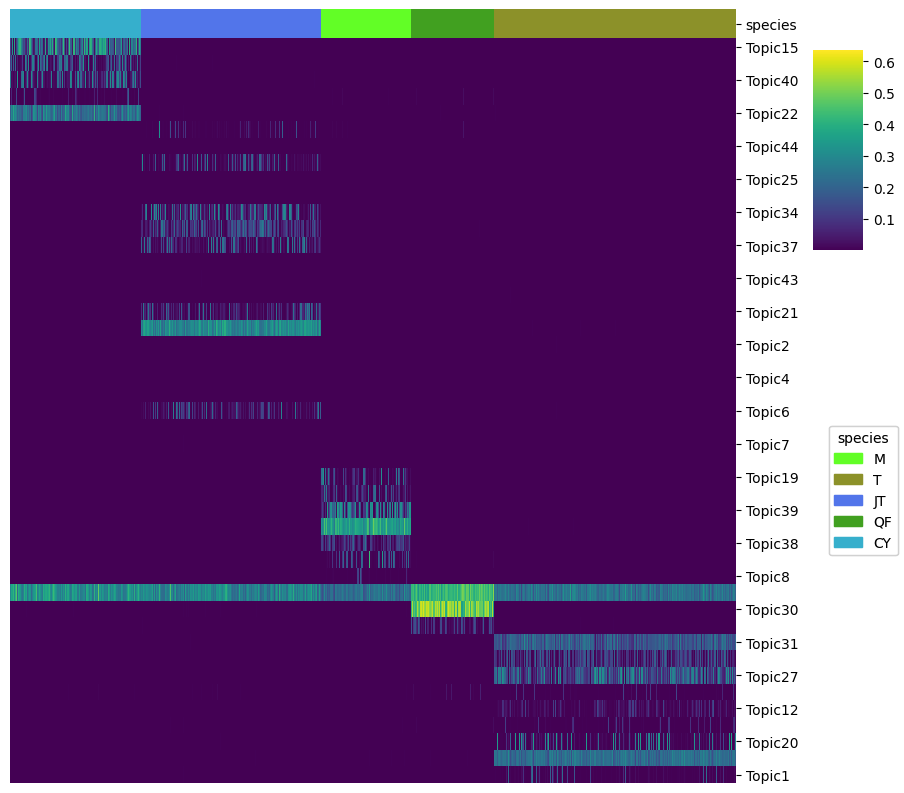

In [60]:
cell_topic_heatmap(
    cistopic_obj,
    variables = ['species'],
    scale = False,
    legend_loc_x = 1.0,
    legend_loc_y = -1.2,
    legend_dist_y = -1,
    figsize = (10, 10)
)

## topic binarization 

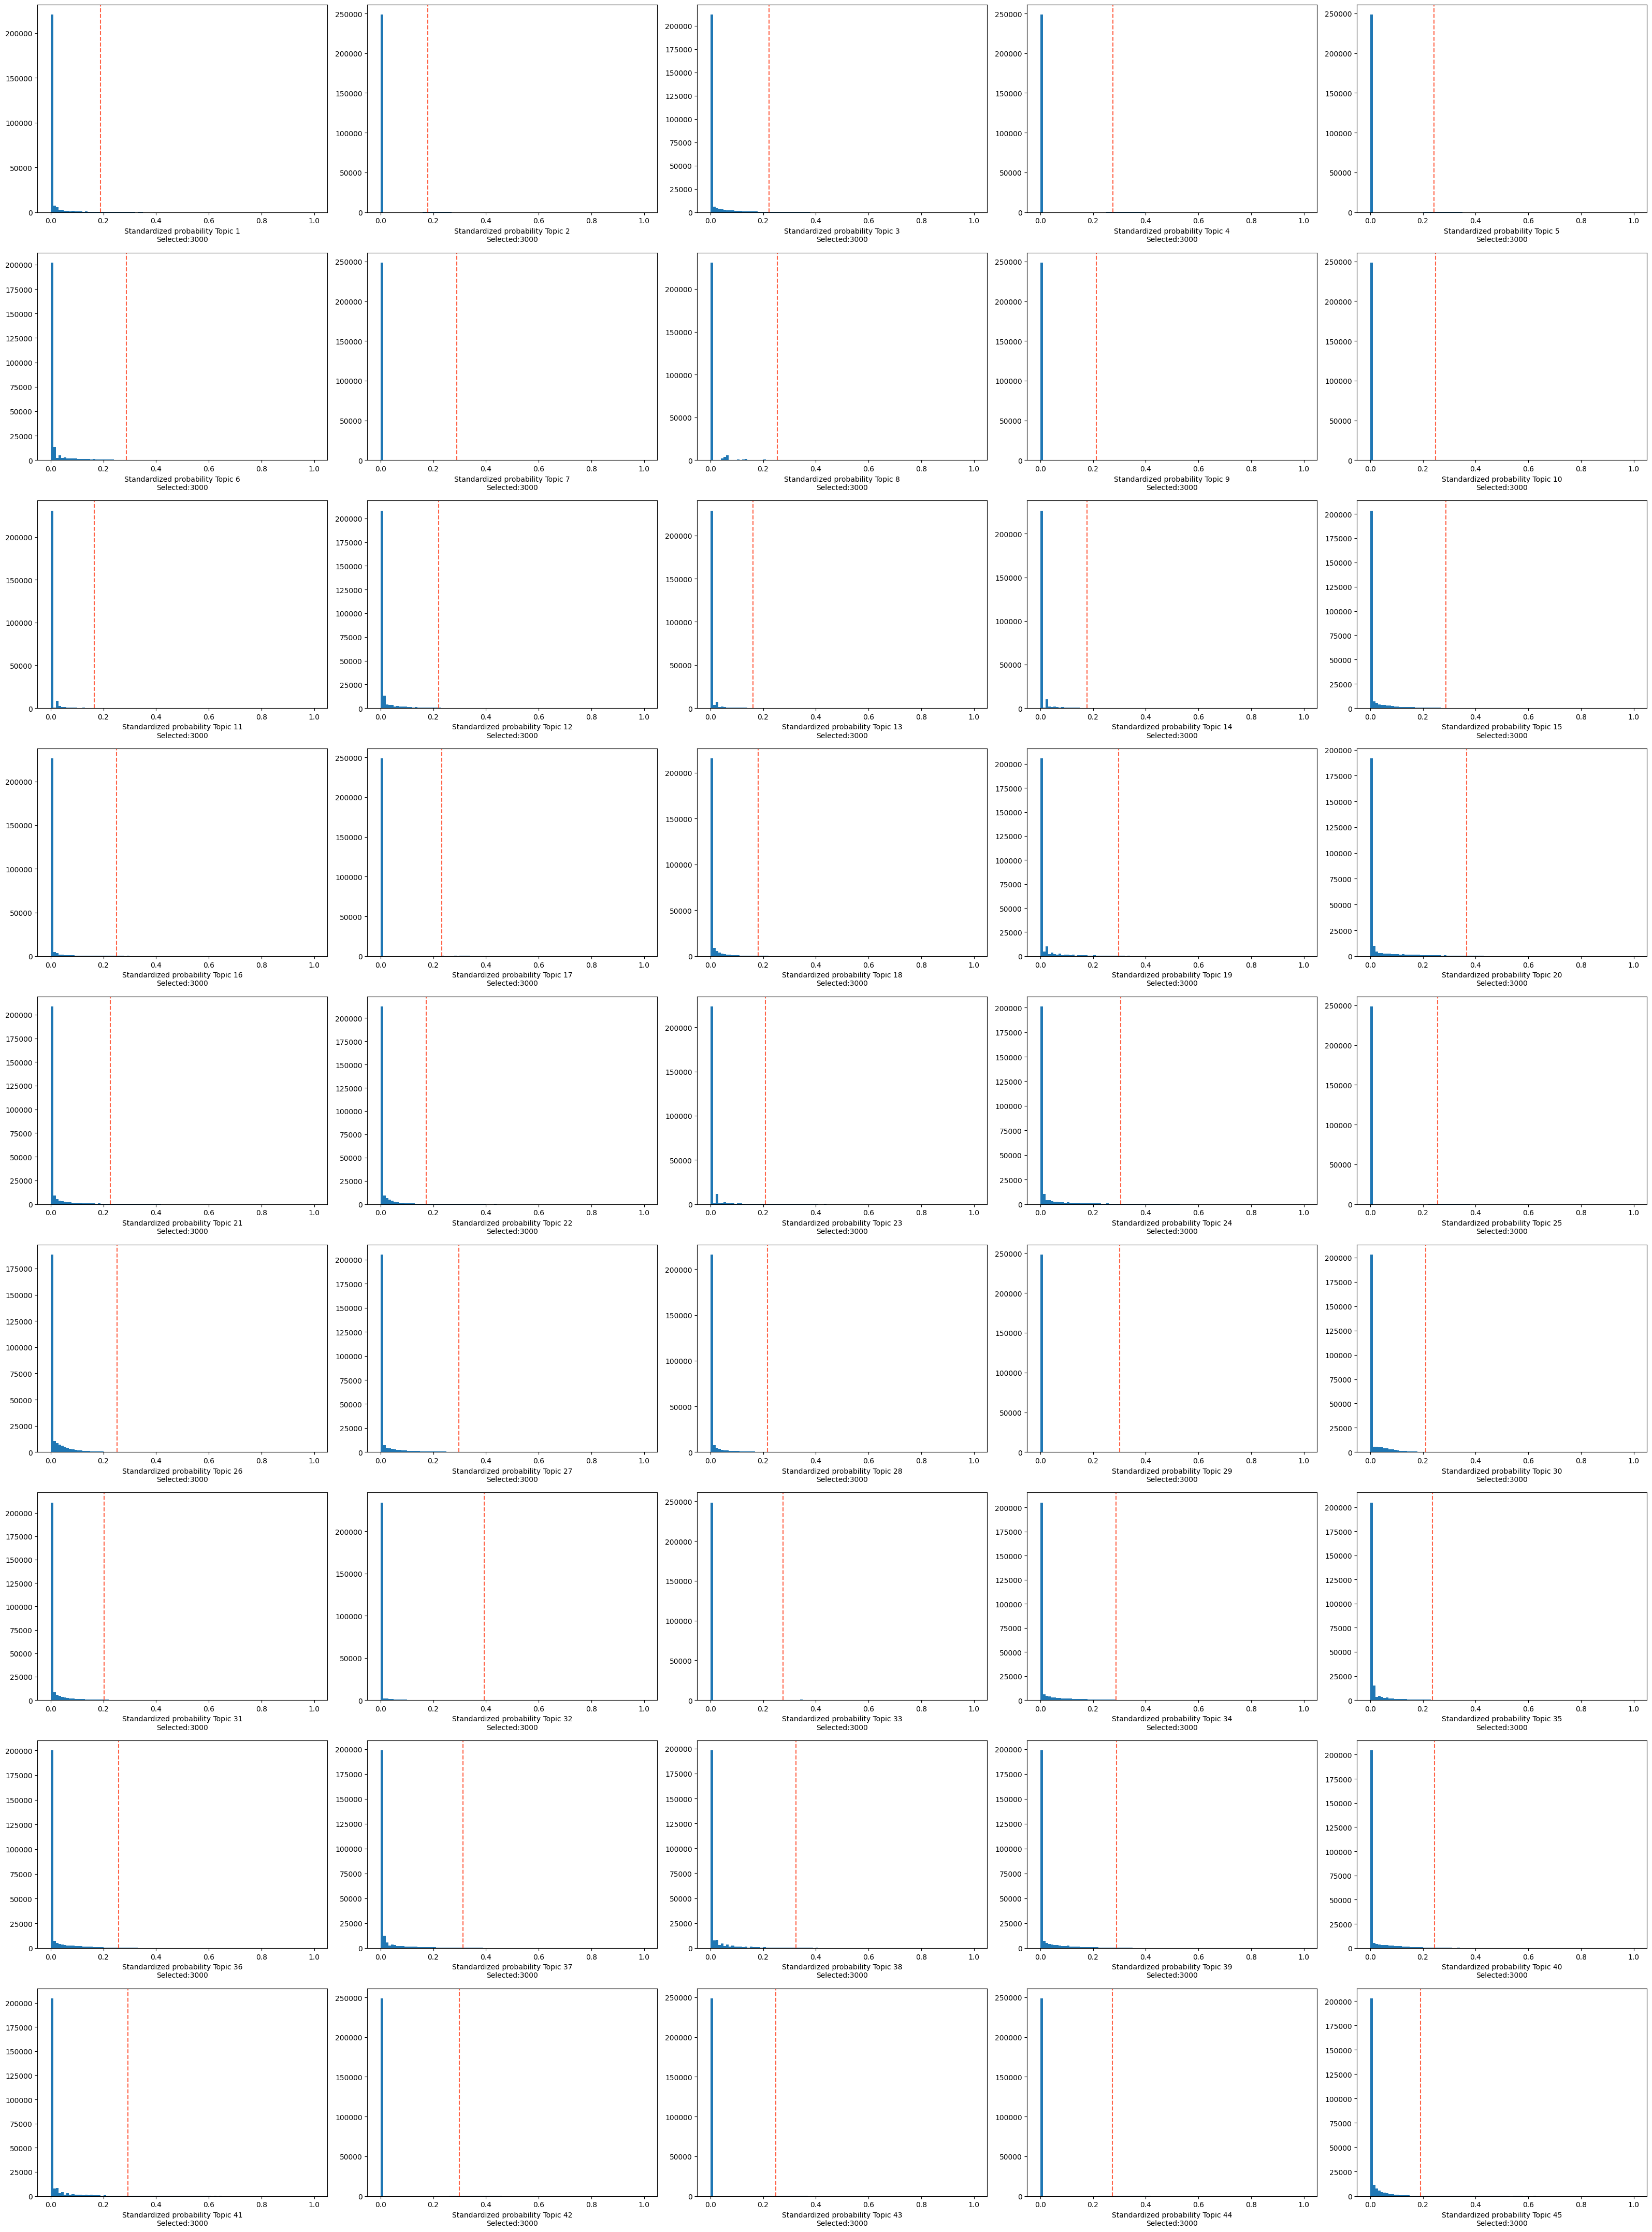

In [61]:
from pycisTopic.topic_binarization import binarize_topics
region_bin_topics_top_3k = binarize_topics(
    cistopic_obj, method='ntop', ntop = 3_000,
    plot=True, num_columns=5
)

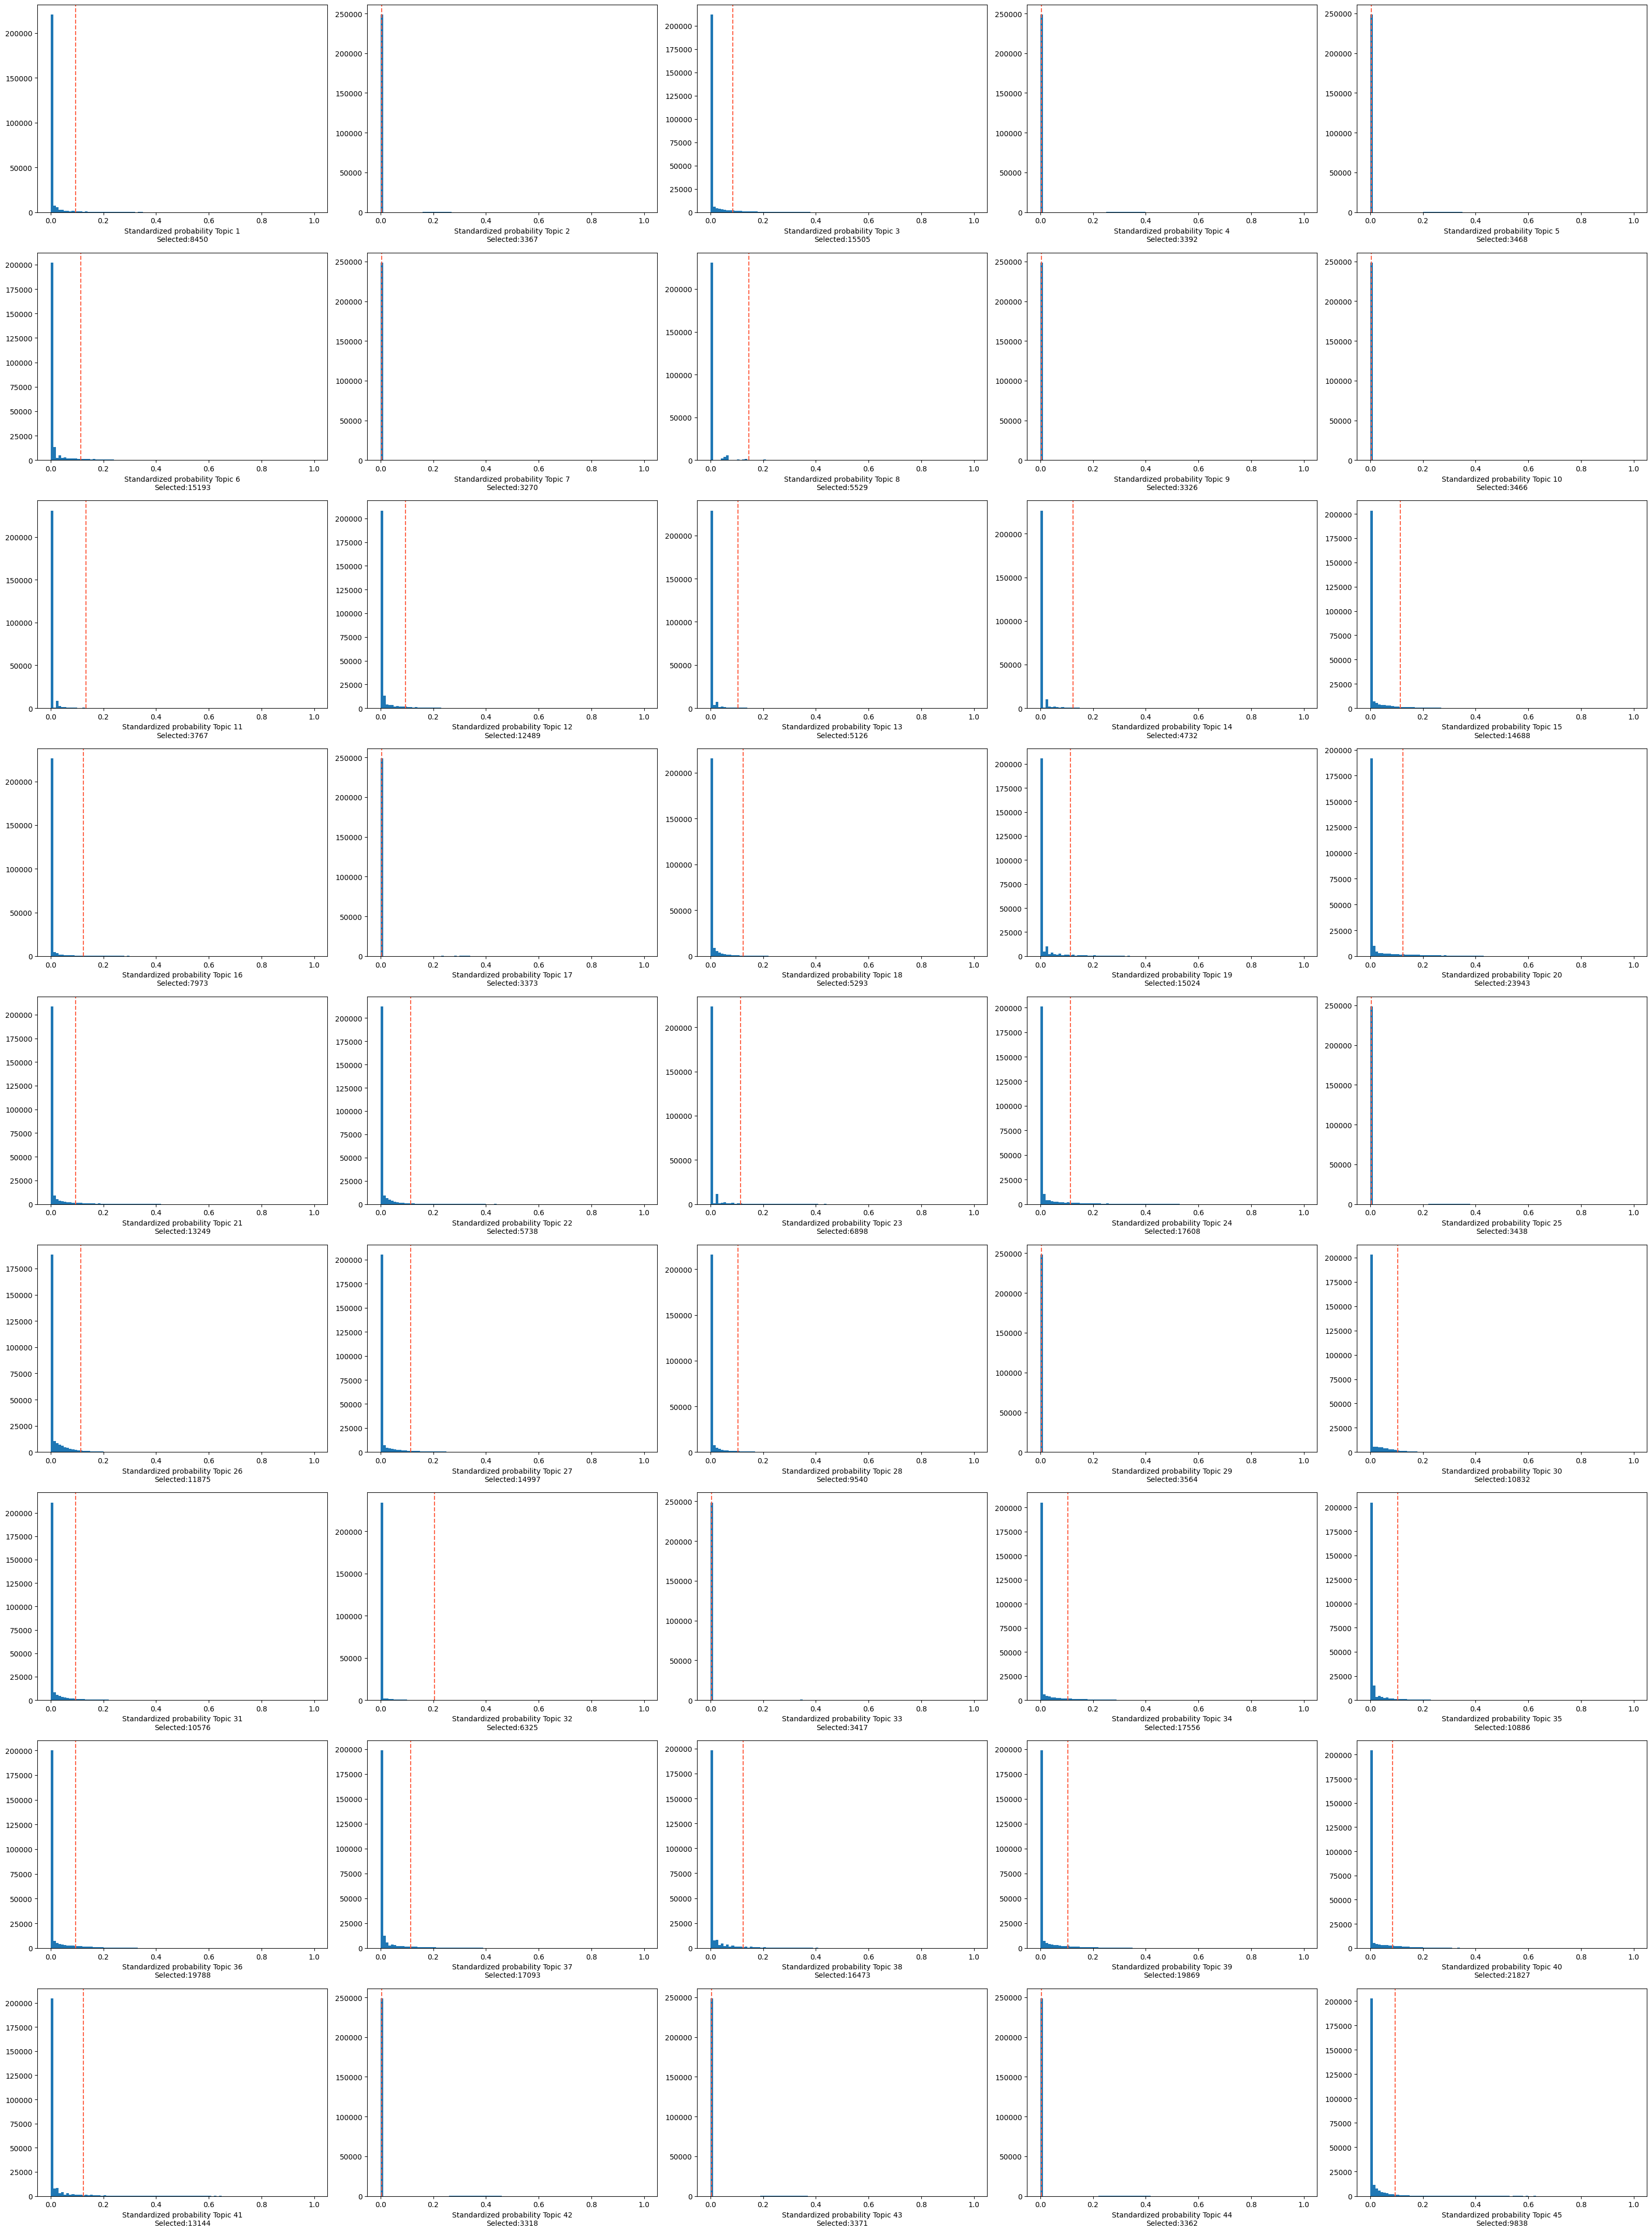

In [62]:
region_bin_topics_otsu = binarize_topics(
    cistopic_obj, method='otsu',
    plot=True, num_columns=5
)

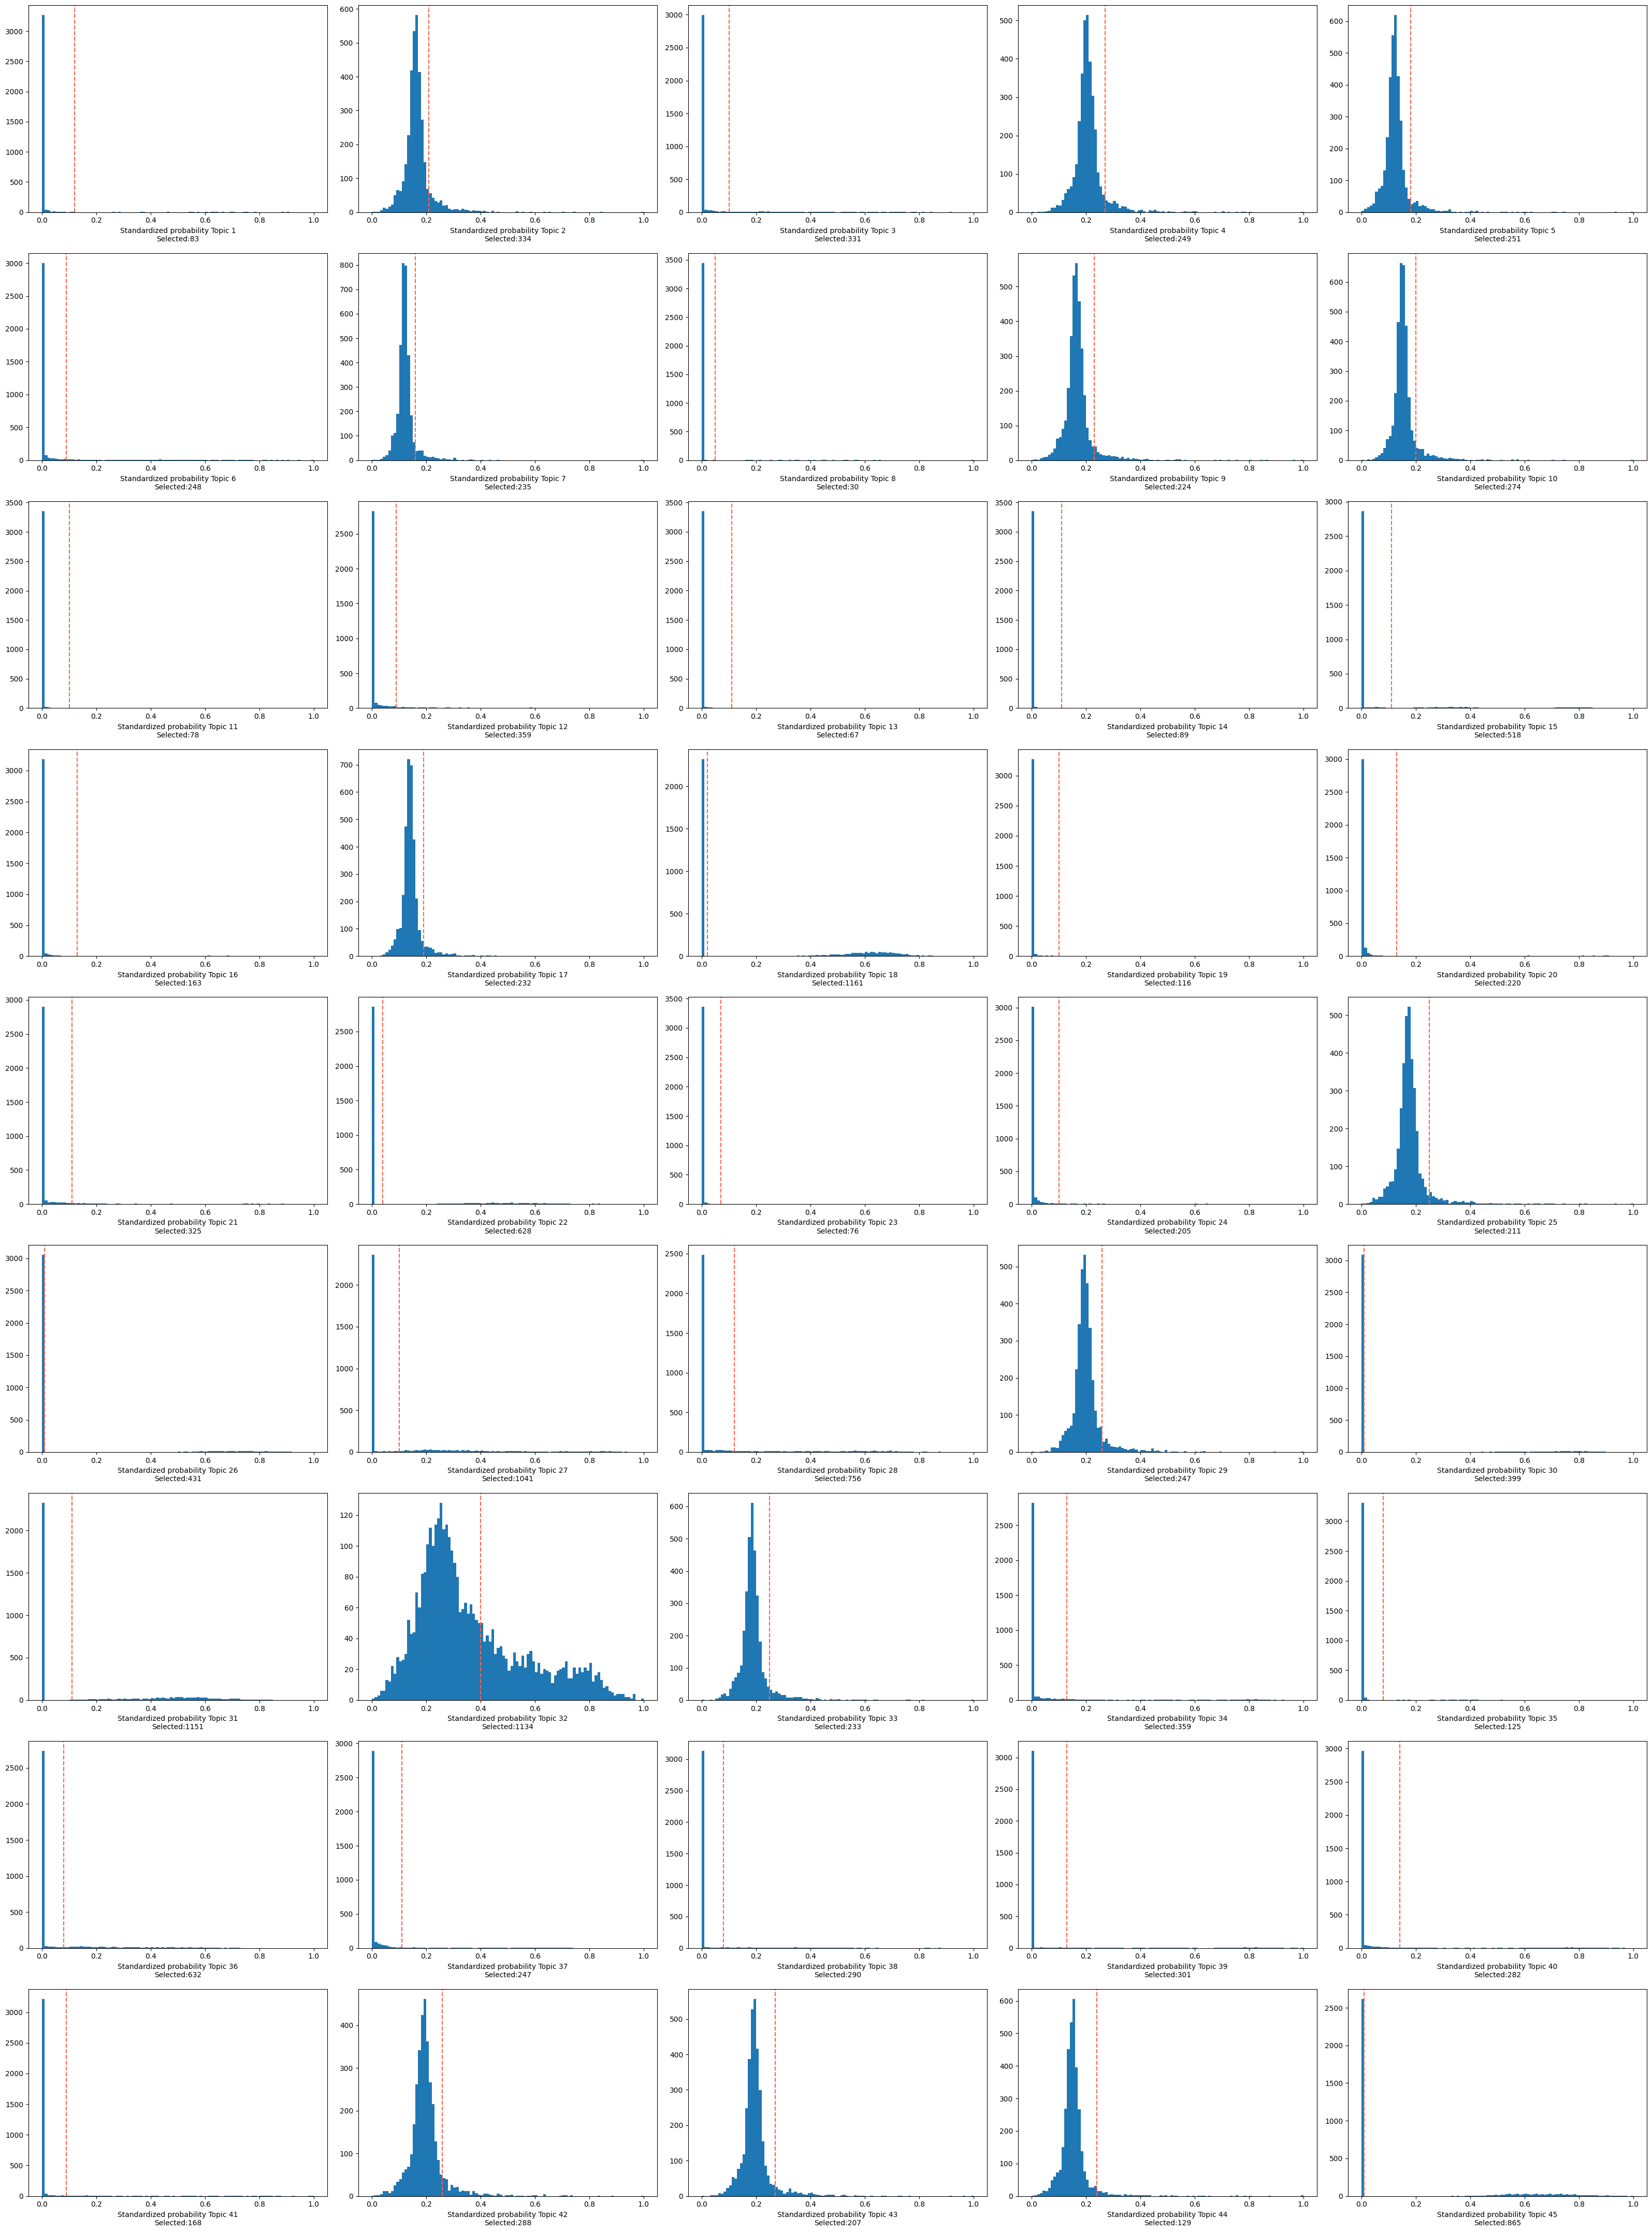

In [63]:
binarized_cell_topic = binarize_topics(
    cistopic_obj,
    target='cell',
    method='li',
    plot=True,
    num_columns=5, nbins=100)

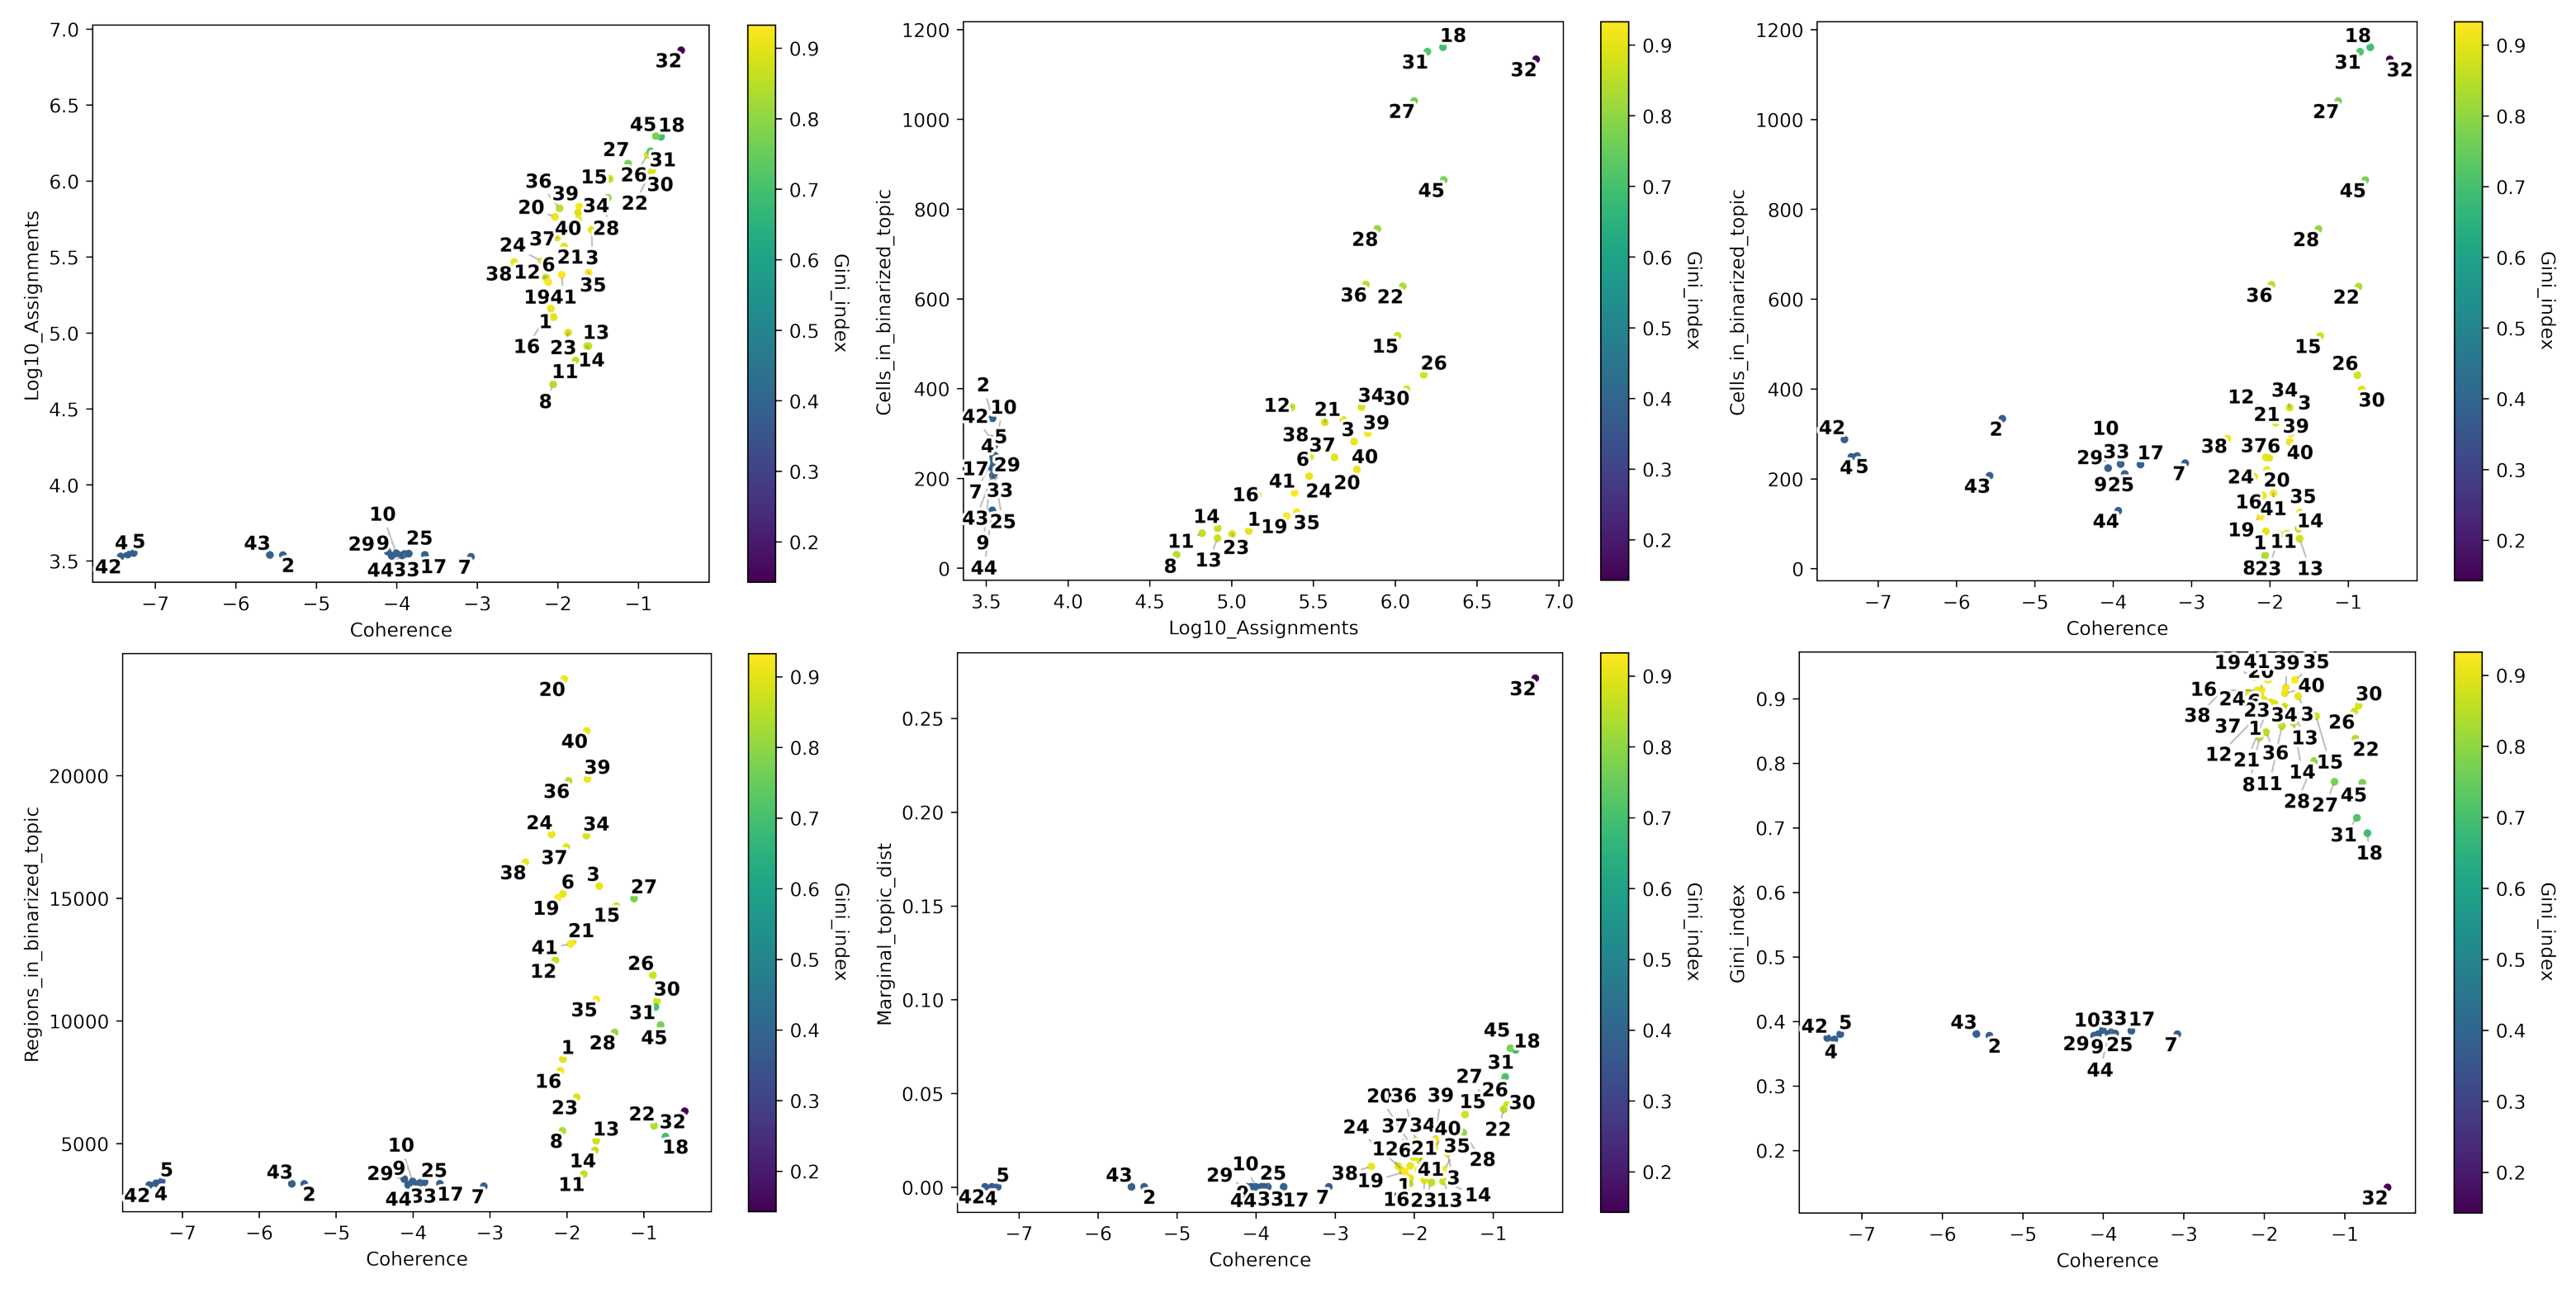

In [64]:
from pycisTopic.topic_qc import compute_topic_metrics, plot_topic_qc, topic_annotation
import matplotlib.pyplot as plt
from pycisTopic.utils import fig2img 


topic_qc_metrics = compute_topic_metrics(cistopic_obj)
fig_dict={}
fig_dict['CoherenceVSAssignments']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Log10_Assignments', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['AssignmentsVSCells_in_bin']=plot_topic_qc(topic_qc_metrics, var_x='Log10_Assignments', var_y='Cells_in_binarized_topic', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSCells_in_bin']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Cells_in_binarized_topic', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSRegions_in_bin']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Regions_in_binarized_topic', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSMarginal_dist']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Marginal_topic_dist', var_color='Gini_index', plot=False, return_fig=True)
fig_dict['CoherenceVSGini_index']=plot_topic_qc(topic_qc_metrics, var_x='Coherence', var_y='Gini_index', var_color='Gini_index', plot=False, return_fig=True)

# Plot topic stats in one figure
fig=plt.figure(figsize=(40, 43))
i = 1
for fig_ in fig_dict.keys():
    plt.subplot(2, 3, i)
    img = fig2img(fig_dict[fig_]) #To convert figures to png to plot together, see .utils.py. This converts the figure to png.
    plt.imshow(img)
    plt.axis('off')
    i += 1
plt.subplots_adjust(wspace=0, hspace=-0.70)
plt.show()

In [66]:
topic_annot = topic_annotation(
    cistopic_obj,
    annot_var='leiden',
    binarized_cell_topic=binarized_cell_topic,
    general_topic_thr = 0.2
)

topic_annot

/home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/statsmodels/stats/weightstats.py:792: RuntimeWarning: divide by zero encountered in scalar divide
  zstat = value / std


,leiden,Ratio_cells_in_topic,Ratio_group_in_population,is_general
Topic1,"1, 3",0.023823,0.238232,False
Topic2,"6, 5, 3",0.095867,0.229908,False
Topic3,"2, 6, 1",0.095006,0.278703,False
Topic4,5,0.07147,0.069747,False
Topic5,3,0.072044,0.110792,False
Topic6,"4, 2",0.071183,0.162457,False
Topic7,,0.067451,0.0,False
Topic8,7,0.008611,0.042193,False
Topic9,4,0.064294,0.060563,False
Topic10,"9, 5",0.078645,0.096154,False


## DARs

2025-06-15 07:57:14,914 cisTopic     INFO     Imputing region accessibility
2025-06-15 07:57:14,915 cisTopic     INFO     Impute region accessibility for regions 0-20000
2025-06-15 07:57:15,252 cisTopic     INFO     Impute region accessibility for regions 20000-40000
2025-06-15 07:57:15,573 cisTopic     INFO     Impute region accessibility for regions 40000-60000
2025-06-15 07:57:15,891 cisTopic     INFO     Impute region accessibility for regions 60000-80000
2025-06-15 07:57:16,202 cisTopic     INFO     Impute region accessibility for regions 80000-100000
2025-06-15 07:57:16,584 cisTopic     INFO     Impute region accessibility for regions 100000-120000
2025-06-15 07:57:16,889 cisTopic     INFO     Impute region accessibility for regions 120000-140000
2025-06-15 07:57:17,252 cisTopic     INFO     Impute region accessibility for regions 140000-160000
2025-06-15 07:57:17,558 cisTopic     INFO     Impute region accessibility for regions 160000-180000
2025-06-15 07:57:17,856 cisTopic     

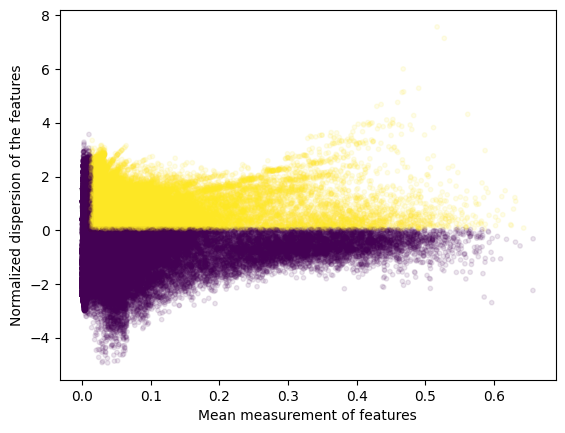

2025-06-15 07:57:36,225 cisTopic     INFO     Done!


In [67]:
from pycisTopic.diff_features import (
    impute_accessibility,
    normalize_scores,
    find_highly_variable_features,
    find_diff_features
)
import numpy as np

imputed_acc_obj = impute_accessibility(
    cistopic_obj,
    selected_cells=None,
    selected_regions=None,
    scale_factor=10**6
)

normalized_imputed_acc_obj = normalize_scores(imputed_acc_obj, scale_factor=10**4)

variable_regions = find_highly_variable_features(
    normalized_imputed_acc_obj,
    min_disp = 0.05,
    min_mean = 0.0125,
    max_mean = 3,
    max_disp = np.inf,
    n_bins=20,
    n_top_features=None,
    plot=True
)

In [69]:
print(len(variable_regions))

markers_dict= find_diff_features(
    cistopic_obj,
    imputed_acc_obj,
    variable='leiden',
    var_features=variable_regions,
    contrasts=None,
    adjpval_thr=0.05,
    log2fc_thr=np.log2(1.5),
    n_cpu=5,
    _temp_dir=None,
    split_pattern = '-'
)

73135


2025-06-15 07:59:09,571	INFO worker.py:1724 -- Started a local Ray instance.


2025-06-15 07:59:09,985 cisTopic     INFO     Subsetting data for 0 (1167 of 3484)
2025-06-15 07:59:15,947 cisTopic     INFO     Computing p-value for 0


(get_wilcox_test_pvalues_ray pid=4188036) /home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/ray/_private/pydantic_compat.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
(get_wilcox_test_pvalues_ray pid=4188036)   from pkg_resources import packaging


2025-06-15 07:59:24,296 cisTopic     INFO     Computing log2FC for 0
2025-06-15 07:59:28,633 cisTopic     INFO     0 done!
2025-06-15 07:59:28,635 cisTopic     INFO     Subsetting data for 1 (444 of 3484)
2025-06-15 07:59:28,747 cisTopic     INFO     Computing p-value for 1
2025-06-15 07:59:36,226 cisTopic     INFO     Computing log2FC for 1
2025-06-15 07:59:36,291 cisTopic     INFO     1 done!
2025-06-15 07:59:36,417 cisTopic     INFO     Subsetting data for 10 (123 of 3484)
2025-06-15 07:59:36,533 cisTopic     INFO     Computing p-value for 10
2025-06-15 07:59:44,176 cisTopic     INFO     Computing log2FC for 10
2025-06-15 07:59:44,236 cisTopic     INFO     10 done!
2025-06-15 07:59:44,381 cisTopic     INFO     Subsetting data for 2 (355 of 3484)
2025-06-15 07:59:44,491 cisTopic     INFO     Computing p-value for 2
2025-06-15 07:59:52,063 cisTopic     INFO     Computing log2FC for 2
2025-06-15 07:59:52,140 cisTopic     INFO     2 done!
2025-06-15 07:59:52,268 cisTopic     INFO     Su

(get_wilcox_test_pvalues_ray pid=4188037) /home/rsun@ZHANGroup.local/anaconda3/envs/scenicplus/lib/python3.11/site-packages/ray/_private/pydantic_compat.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81. [repeated 4x across cluster]
(get_wilcox_test_pvalues_ray pid=4188037)   from pkg_resources import packaging [repeated 4x across cluster]


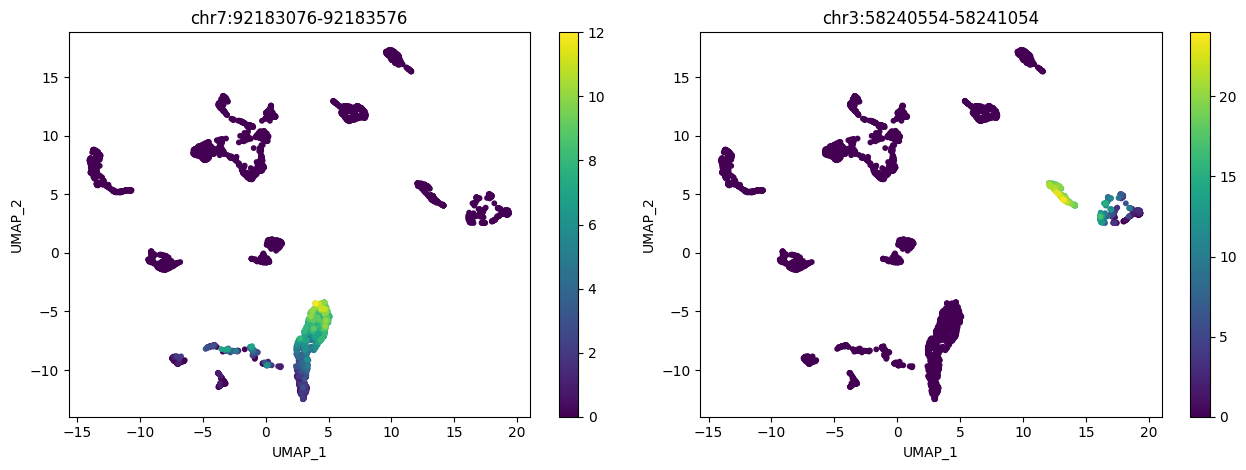

Number of DARs found:
---------------------
  0: 18177
  1: 17078
  10: 16997
  2: 27245
  3: 15716
  4: 26941
  5: 15730
  6: 18659
  7: 1813
  8: 5128
  9: 11917


In [70]:
from pycisTopic.clust_vis import plot_imputed_features
plot_imputed_features(
    cistopic_obj,
    reduction_name='UMAP',
    imputed_data=imputed_acc_obj,
    features=[markers_dict[x].index.tolist()[0] for x in ['0','5']],
    scale=False,
    num_columns=4
)

print("Number of DARs found:")
print("---------------------")
for x in markers_dict:
    print(f"  {x}: {len(markers_dict[x])}")

## save region sets

In [71]:
os.makedirs(os.path.join(out_dir, "region_sets"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "region_sets", "Topics_otsu"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "region_sets", "Topics_top_3k"), exist_ok = True)
os.makedirs(os.path.join(out_dir, "region_sets", "DARs_cell_type"), exist_ok = True)
from pycisTopic.utils import region_names_to_coordinates

for topic in region_bin_topics_otsu:
    region_names_to_coordinates(
        region_bin_topics_otsu[topic].index
    ).sort_values(
        ["Chromosome", "Start", "End"]
    ).to_csv(
        os.path.join(out_dir, "region_sets", "Topics_otsu", f"{topic}.bed"),
        sep = "\t",
        header = False, index = False
    )

for topic in region_bin_topics_top_3k:
    region_names_to_coordinates(
        region_bin_topics_top_3k[topic].index
    ).sort_values(
        ["Chromosome", "Start", "End"]
    ).to_csv(
        os.path.join(out_dir, "region_sets", "Topics_top_3k", f"{topic}.bed"),
        sep = "\t",
        header = False, index = False
    )

for cell_type in markers_dict:
    region_names_to_coordinates(
        markers_dict[cell_type].index
    ).sort_values(
        ["Chromosome", "Start", "End"]
    ).to_csv(
        os.path.join(out_dir, "region_sets", "DARs_cell_type", f"{cell_type}.bed"),
        sep = "\t",
        header = False, index = False
    )

In [72]:
import pickle
pickle.dump(
    cistopic_obj,
    open(os.path.join(out_dir, "cistopic_obj.pkl"), "wb")
)

In [ ]:
c